<a href="https://colab.research.google.com/github/GoneRamuCena/Optimizing-Profitable-Trades-in-Forex-Market-using-ML-and-NN/blob/main/Optimizing_Profitable_Trades_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install category_encoders
!pip install catboost
!pip install xgboost
!pip install lightgbm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 10.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from category_encoders import TargetEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay,precision_recall_curve,auc,roc_curve, roc_auc_score,accuracy_score
from sklearn.model_selection import KFold

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

from sklearn.tree import DecisionTreeClassifier

from sklearn.inspection import permutation_importance

from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [ ]:
# downloading the excel dataset from Google Sheets
file_id = "1MLwsNM6MOzivlvm6hRKhgSTUbMgsPiDgkGZaIqraD6Y"
gid = "761856969"   # 2nd tab gid

# Create export link
sheet_url = f"https://docs.google.com/spreadsheets/d/{file_id}/export?format=csv&gid={gid}"

# Read into pandas dataframe
df = pd.read_csv(sheet_url)

# Display top rows
df.head()

,Trade Entry Time,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,4H R_S price,D R_S price,W R_S price,R_S tf,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
0,1/3/2025,BTCUSD,Up,Up,Up,Reversal,NaN,91678.2,NaN,D,...,Wide,54.68345,40.552060,29.625110,Up,Down,Down,Down,Up,Down
1,1/10/2025 7:30:00,BTCUSD,Up,Up,Up,Reversal,NaN,91678.2,NaN,D,...,Average,42.92176,45.602112,28.517125,Down,Up,Down,Down,Down,Down
2,1/13/2025 23:30:00,BTCUSD,Up,Up,Up,Reversal,NaN,91678.2,NaN,D,...,Average,48.83411,73.791157,43.626378,just up,Down,Down,Down,Down,Down
3,1/14/2025,BTCUSD,Up,Up,Up,Reversal,NaN,91678.2,NaN,D,...,Wide,51.55712,53.163940,39.770580,just up,Down,Down,Down,Up,Down
4,1/21/2025 19:30:00,BTCUSD,Down,Up,Up,Reversal,NaN,106673.2,NaN,D,...,Average,61.89324,66.238134,48.787950,Up,Down,Up,Up,Up,Up


# 1. Defining Problem Statement



* In a world of Trading, no trader is 100% sure that he will get profited in all trades.
* Optimizing the profitable Trades means given the tradesetup details in trading whether the trader is going to be profitable or not. Just like patient comes to hospital and gets medical report then based on that model predicts him as cancer patient or healthy person. Here, a trade opportunity comes and trader enter details then after sometime he may get profit or loss. Then why optimizing profitable trades means here given trade opportunity details model may predict loss or profit. so, when model predict it's as profitable trade then only i will enter into trade else i avoid the trade.
* Usually In this data, Trader entered all trades near support or resistance lines not at random time and place.
* So, When the trader see an opportunity at resistance or support, he takes a look at technical analysis details (i.e  4H time frame market trend, D timeframe market trend, W timeframe market trend, resistance/support timeframe, candlestick pattern formed,candlestick pattern confirmation, how many times resistance/support got hitted ).
* Followed by it, he also observes technical indicator signals (i.e. major indicators used are CPR,EMA,Parabolic Sar,Bollinger Band,Ichimoku,RSI, Stochastic Oscillator & super trend)
* After all these confirmation he enters the trade. But, he is not sure that he is going to have a profitable trade or not.
* Hence, given the Trade entry detail (technical analysis details, technical indicators details ) we have to find whether the next trade is going to profitable or not .


## Some questions
* 1. will trade entry analysis be different for different currency pairs ?
    * No, because technical analysis works on every currency pairs same. It's  just like technical analysis works same on stocks and just like technical indicators works same on every stock or currency pairs.
* 2. Are we entering into market in all times ?
  * Here we are entering into market based on Resistance & Support strategy.It means we enter in market only near the resistance or support lines.
  * So, we are not entering into market in all times rather we only enter a trade when trading opportunity comes.
* 3. Why currency pair included as feature even technical analysis same for all currency pairs ?
  * Voltatility of currency pairs matters in hitting rate of profit/Sl. Example Gold,BTc are most traded so, they have high hitting ratio of profit/SL but for Audusd and usdcad they are least preferable currencypairs so volatality will be low thus hitting ratio will be low.

# DataSet Description
* We collected forex trade entry details of AUDUSD, EURUSD, GBPUSD, NZDUSD, USDCAD, Gold & Bitcoin from January 2025 to present.
* Following are the Dataset column details :
1. Trade Entry Time : Time at which trade was excuted
2. Currency Pair : currency pair in which we entered for trade.
3. 4H Trend : Market movement from past few hours in 4 hour Timeframe
4. D Trend : Market movement from past few days in Day Timeframe
5. W Trend : Market movement from past few weeks in Weeks Timeframe
6. Reversal/Retrace : type of market movement at resistance/support.
7. 4H R_S Price : 4hour timeframe Resistance/suppport price level
8. D R_S Price : Day  timeframe Resistance/suppport price level
9. W R_S Price : Week timeframe Resistance/suppport price level
10. R_S tf : timeframe of Resistance/support where we entered trade.
11. R_S : indicating whether it is a resistance line or support line.
12. Candlestick pattern : details of different candlestick patterns of market at trade entry time.
13. Candlestick confirmation : whether candlestick pattern confirmed or not when we are entering the trade.
14. no. of times R/S hitted : how many times market touched that resistance/support line previously.
15. Trade Entry TF : Market Timeframe in which we entered the trade.
16. Buy/Sell or Long/short : Type of Trade entered. In Buy or Long type of trade, we expect market to go up. Whereas in Sell or short type of trade, we expect market to go down.
17. entry : Price at which we enter the trade.
18. exit : price at which we exited the trade.
19. lot size : no. of lot size used for trading. It's just like investment amount.
20. pips difference : market price difference between entry and exit time. Simply, How far market moved.
21. return for 0.01 lotsize : profit/loss amount (in $) we got from trade using 0.01 lotsize.
22. return for 1 lotsize : profit/loss amount we got from trade using 1 lotsize.
23. Profit/SL : indicating entered trade got profit or stoploss(loss).
24. Trade Entry direction : Direction in which trade got excuted. For Buy(long) type trade, trade entry direction will be up. Whereas for Sell(short) type trade , trade entry direction will be down.
25. Market direction : Direction in which market acutually went.
26. CPR type : size of CPR indicator.
27. RSI : rsi indicator value.
28. Stochastic_buyers_signal : Stochastic oscillator indicator buyer's value.
29. Stochastic_sellers_signal : Stochastic oscillator indicator seller's value.
30. EMA 14 : signal given by moving average indicator, whether market go up or down.
31. SAR : signal given by Parabolic SAR indicator, whether market go up or down.
32. Bollinger Band : signal given by Bollinger Band indicator, whether market go up or down.
33. Ichimoku_line : signal given by ichimoku indicator's lines, whether market go up or down.
34. Ichimoku_cloud : signal given by ichimoku indicator's cloud, whether market go up or down.
35. Super Trend : signal given by Super Trend indicator, whether market go up or down.

# Cleaning the dataset

In [ ]:
df.columns

Index(['Trade Entry Time', 'Currency Pair', '4H Trend', 'D Trend', 'W Trend',
       'Reversal/Retrace', '4H R_S price', 'D R_S price', 'W R_S price',
       'R_S tf', 'R_S', 'Candlestick pattern', 'Candlestick confirmation',
       'no. of times R/S hitted', 'Trade Entry TF', 'Buy/Sell', 'entry',
       'exit', 'lot size', 'pips difference', 'return for 0.01 lotsize',
       'return for 1 lotsize', 'Profit/SL', 'Trade Entry direction',
       'Market direction', 'CPR type', 'RSI', 'Stochastic_buyers_signal',
       'Stochastic_sellers_signal', 'EMA 14', 'SAR', 'Bollinger Band',
       'Ichimoku_line', 'Ichimoku_cloud', 'Super Trend'],
      dtype='object')

In [ ]:
df.shape

(994, 35)

In [ ]:
df["Profit/SL"].value_counts()

,count
Profit/SL,
,758
SL,131
1:2 P,105


In [ ]:
df.isna().sum(axis=1).tail(10)

,0
984,32
985,32
986,32
987,32
988,32
989,32
990,32
991,32
992,32
993,32


In [ ]:
df[234:]

,Trade Entry Time,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,4H R_S price,D R_S price,W R_S price,R_S tf,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
234,10/24/2025 9:00:00,USDCAD,Up,Up,Up,Retracement,NaN,1.39838,NaN,D,...,Narrow,53.08905,78.76254,74.46447,just up,Down,Down,Down,Down,Down
235,10/27/2025 13:00:00,USDCAD,Up,Up,Up,Retracement,NaN,1.39838,NaN,D,...,Narrow,47.49210,38.13683,21.19870,Down,Down,Down,Down,Down,Down
236,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df[234:].isnull()

,Trade Entry Time,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,4H R_S price,D R_S price,W R_S price,R_S tf,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
234,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
235,False,False,False,False,False,False,True,False,True,False,...,False,False,False,False,False,False,False,False,False,False
236,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
237,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
238,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
989,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
990,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
991,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
992,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [ ]:
df = df[:236]
df.tail()

,Trade Entry Time,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,4H R_S price,D R_S price,W R_S price,R_S tf,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
231,9/17/2025 1:00:00,USDCAD,Up,Up,No clarity,Reversal,1.37329,NaN,NaN,4H,...,Average,30.33689,14.87455,8.400186,Down,Down,Down,Down,Down,Down
232,9/30/2025 21:00:00,USDCAD,Up,Up,No clarity,Retracement,1.39181,NaN,NaN,4H,...,Average,59.66039,59.60784,47.293040,just up,Up,Down,Down,Up,Up
233,10/13/2025 5:00:00,USDCAD,Up,Up,Up,Retracement,NaN,1.39838,NaN,D,...,Narrow,57.26425,67.26190,61.838620,Up,Up,Up,Up,Up,Up
234,10/24/2025 9:00:00,USDCAD,Up,Up,Up,Retracement,NaN,1.39838,NaN,D,...,Narrow,53.08905,78.76254,74.464470,just up,Down,Down,Down,Down,Down
235,10/27/2025 13:00:00,USDCAD,Up,Up,Up,Retracement,NaN,1.39838,NaN,D,...,Narrow,47.49210,38.13683,21.198700,Down,Down,Down,Down,Down,Down


In [ ]:
df.isna().sum()

,0
Trade Entry Time,0
Currency Pair,0
4H Trend,0
D Trend,0
W Trend,0
Reversal/Retrace,0
4H R_S price,111
D R_S price,155
W R_S price,206
R_S tf,0


In [ ]:
df.dropna(axis = 1,inplace = True)
df.head()

,Trade Entry Time,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
0,1/3/2025,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Engulfing,Instance,...,Wide,54.68345,40.552060,29.625110,Up,Down,Down,Down,Up,Down
1,1/10/2025 7:30:00,BTCUSD,Up,Up,Up,Reversal,D,Support,Other Bullish,Instance,...,Average,42.92176,45.602112,28.517125,Down,Up,Down,Down,Down,Down
2,1/13/2025 23:30:00,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Harami,Instance,...,Average,48.83411,73.791157,43.626378,just up,Down,Down,Down,Down,Down
3,1/14/2025,BTCUSD,Up,Up,Up,Reversal,D,Support,Tweezer bottom,Late,...,Wide,51.55712,53.163940,39.770580,just up,Down,Down,Down,Up,Down
4,1/21/2025 19:30:00,BTCUSD,Down,Up,Up,Reversal,D,Resistance,hanging man,Instance,...,Average,61.89324,66.238134,48.787950,Up,Down,Up,Up,Up,Up


In [ ]:
df.isna().sum()

,0
Trade Entry Time,0
Currency Pair,0
4H Trend,0
D Trend,0
W Trend,0
Reversal/Retrace,0
R_S tf,0
R_S,0
Candlestick pattern,0
Candlestick confirmation,0


# Analysis Basic metrics of Dataset

In [ ]:
# finding shape of datasets
df.shape

(236, 32)

* There are 236 rows, 32 columns in given dataset.
* In given dataset, I did 236 trading transactions.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 236 entries, 0 to 235
Data columns (total 32 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Trade Entry Time           236 non-null    object 
 1   Currency Pair              236 non-null    object 
 2   4H Trend                   236 non-null    object 
 3   D Trend                    236 non-null    object 
 4   W Trend                    236 non-null    object 
 5   Reversal/Retrace           236 non-null    object 
 6   R_S tf                     236 non-null    object 
 7   R_S                        236 non-null    object 
 8   Candlestick pattern        236 non-null    object 
 9   Candlestick confirmation   236 non-null    object 
 10  no. of times R/S hitted    236 non-null    float64
 11  Trade Entry TF             236 non-null    object 
 12  Buy/Sell                   236 non-null    object 
 13  entry                      236 non-null    float64

In [ ]:
# Names of column in the given dataset
df.columns

Index(['Trade Entry Time', 'Currency Pair', '4H Trend', 'D Trend', 'W Trend',
       'Reversal/Retrace', 'R_S tf', 'R_S', 'Candlestick pattern',
       'Candlestick confirmation', 'no. of times R/S hitted', 'Trade Entry TF',
       'Buy/Sell', 'entry', 'exit', 'lot size', 'pips difference',
       'return for 0.01 lotsize', 'return for 1 lotsize', 'Profit/SL',
       'Trade Entry direction', 'Market direction', 'CPR type', 'RSI',
       'Stochastic_buyers_signal', 'Stochastic_sellers_signal', 'EMA 14',
       'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud',
       'Super Trend'],
      dtype='object')

In [ ]:
# finding the no. of unique values in each column
df.nunique()

,0
Trade Entry Time,214
Currency Pair,7
4H Trend,3
D Trend,3
W Trend,3
Reversal/Retrace,2
R_S tf,3
R_S,2
Candlestick pattern,14
Candlestick confirmation,3


In [ ]:
cat_col =  ['Currency Pair', '4H Trend', 'D Trend', 'W Trend','Reversal/Retrace', 'R_S tf', 'R_S', 'Candlestick pattern','Candlestick confirmation',
              'no. of times R/S hitted','Trade Entry TF', 'Buy/Sell', 'lot size','Profit/SL', 'Trade Entry direction', 'Market direction', 'CPR type',
              'EMA 14', 'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud','Super Trend']

num_col = ['Trade Entry Time','entry', 'exit','pips difference', 'return for 0.01 lotsize',
              'return for 1 lotsize', 'RSI', 'Stochastic_buyers_signal', 'Stochastic_sellers_signal']

### Detailing About Columns


In [ ]:
df[cat_col].head(5)

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,Profit/SL,Trade Entry direction,Market direction,CPR type,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
0,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Engulfing,Instance,2.0,...,SL,Up,Down,Wide,Up,Down,Down,Down,Up,Down
1,BTCUSD,Up,Up,Up,Reversal,D,Support,Other Bullish,Instance,4.0,...,SL,Up,Down,Average,Down,Up,Down,Down,Down,Down
2,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Harami,Instance,5.0,...,1:2 P,Up,Up,Average,just up,Down,Down,Down,Down,Down
3,BTCUSD,Up,Up,Up,Reversal,D,Support,Tweezer bottom,Late,3.0,...,1:2 P,Up,Up,Wide,just up,Down,Down,Down,Up,Down
4,BTCUSD,Down,Up,Up,Reversal,D,Resistance,hanging man,Instance,2.0,...,1:2 P,Down,Down,Average,Up,Down,Up,Up,Up,Up


In [ ]:
# unique values in each columns

for i in cat_col:
  print(i,":")
  print(sorted(df[i].unique()),"\n\n")

Currency Pair :
['AUDUSD', 'BTCUSD', 'EURUSD', 'GBPUSD', 'NZDUSD', 'USDCAD', 'XAUUSD'] 


4H Trend :
['Down', 'No clarity', 'Up'] 


D Trend :
['Down', 'No clarity', 'Up'] 


W Trend :
['Down', 'No clarity', 'Up'] 


Reversal/Retrace :
['Retracement', 'Reversal'] 


R_S tf :
['4H', 'D', 'W'] 


R_S :
['Resistance', 'Support'] 


Candlestick pattern :
['Bearish Engulfing', 'Bearish Harami', 'Bullish Engulfing', 'Bullish Harami', 'Evening star', 'Hammer', 'Inverted hammer', 'Morning star', 'Other Bearish', 'Other Bullish', 'Tweezer Top', 'Tweezer bottom ', 'hanging man', 'shooting star'] 


Candlestick confirmation :
['Instance', 'Late', 'No'] 


no. of times R/S hitted :
[np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(10.0)] 


Trade Entry TF :
['4H', 'D', 'W'] 


Buy/Sell :
['Buy', 'Sell'] 


lot size :
[np.float64(0.01)] 


Profit/SL :
['1:2 P', 'SL'] 


Trade Entry direction :
['Down', 'Up'] 


Market 

In [ ]:
for i in cat_col :
  print("*************************")
  print("***********",i,"*********")
  print(df[i].value_counts(),"\n\n")

*************************
*********** Currency Pair *********
Currency Pair
XAUUSD    38
NZDUSD    36
EURUSD    34
AUDUSD    33
BTCUSD    33
GBPUSD    32
USDCAD    30
Name: count, dtype: int64 


*************************
*********** 4H Trend *********
4H Trend
Up            142
Down           91
No clarity      3
Name: count, dtype: int64 


*************************
*********** D Trend *********
D Trend
Up            131
Down           74
No clarity     31
Name: count, dtype: int64 


*************************
*********** W Trend *********
W Trend
Up            143
No clarity     56
Down           37
Name: count, dtype: int64 


*************************
*********** Reversal/Retrace *********
Reversal/Retrace
Reversal       147
Retracement     89
Name: count, dtype: int64 


*************************
*********** R_S tf *********
R_S tf
4H    125
D      81
W      30
Name: count, dtype: int64 


*************************
*********** R_S *********
R_S
Support       137
Resistance     99

In [ ]:
df[num_col].head(5)

,Trade Entry Time,entry,exit,pips difference,return for 0.01 lotsize,return for 1 lotsize,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal
0,1/3/2025,96062.7,90713.1,-5349.6,-53.50,-5350.0,54.68345,40.552060,29.625110
1,1/10/2025 7:30:00,93951.5,89977.6,-3973.9,-39.74,-3974.0,42.92176,45.602112,28.517125
2,1/13/2025 23:30:00,94093.0,106022.0,11929.0,119.29,11929.0,48.83411,73.791157,43.626378
3,1/14/2025,96267.1,107017.3,10750.2,107.50,10750.0,51.55712,53.163940,39.770580
4,1/21/2025 19:30:00,105385.6,95631.9,9753.7,97.54,9754.0,61.89324,66.238134,48.787950


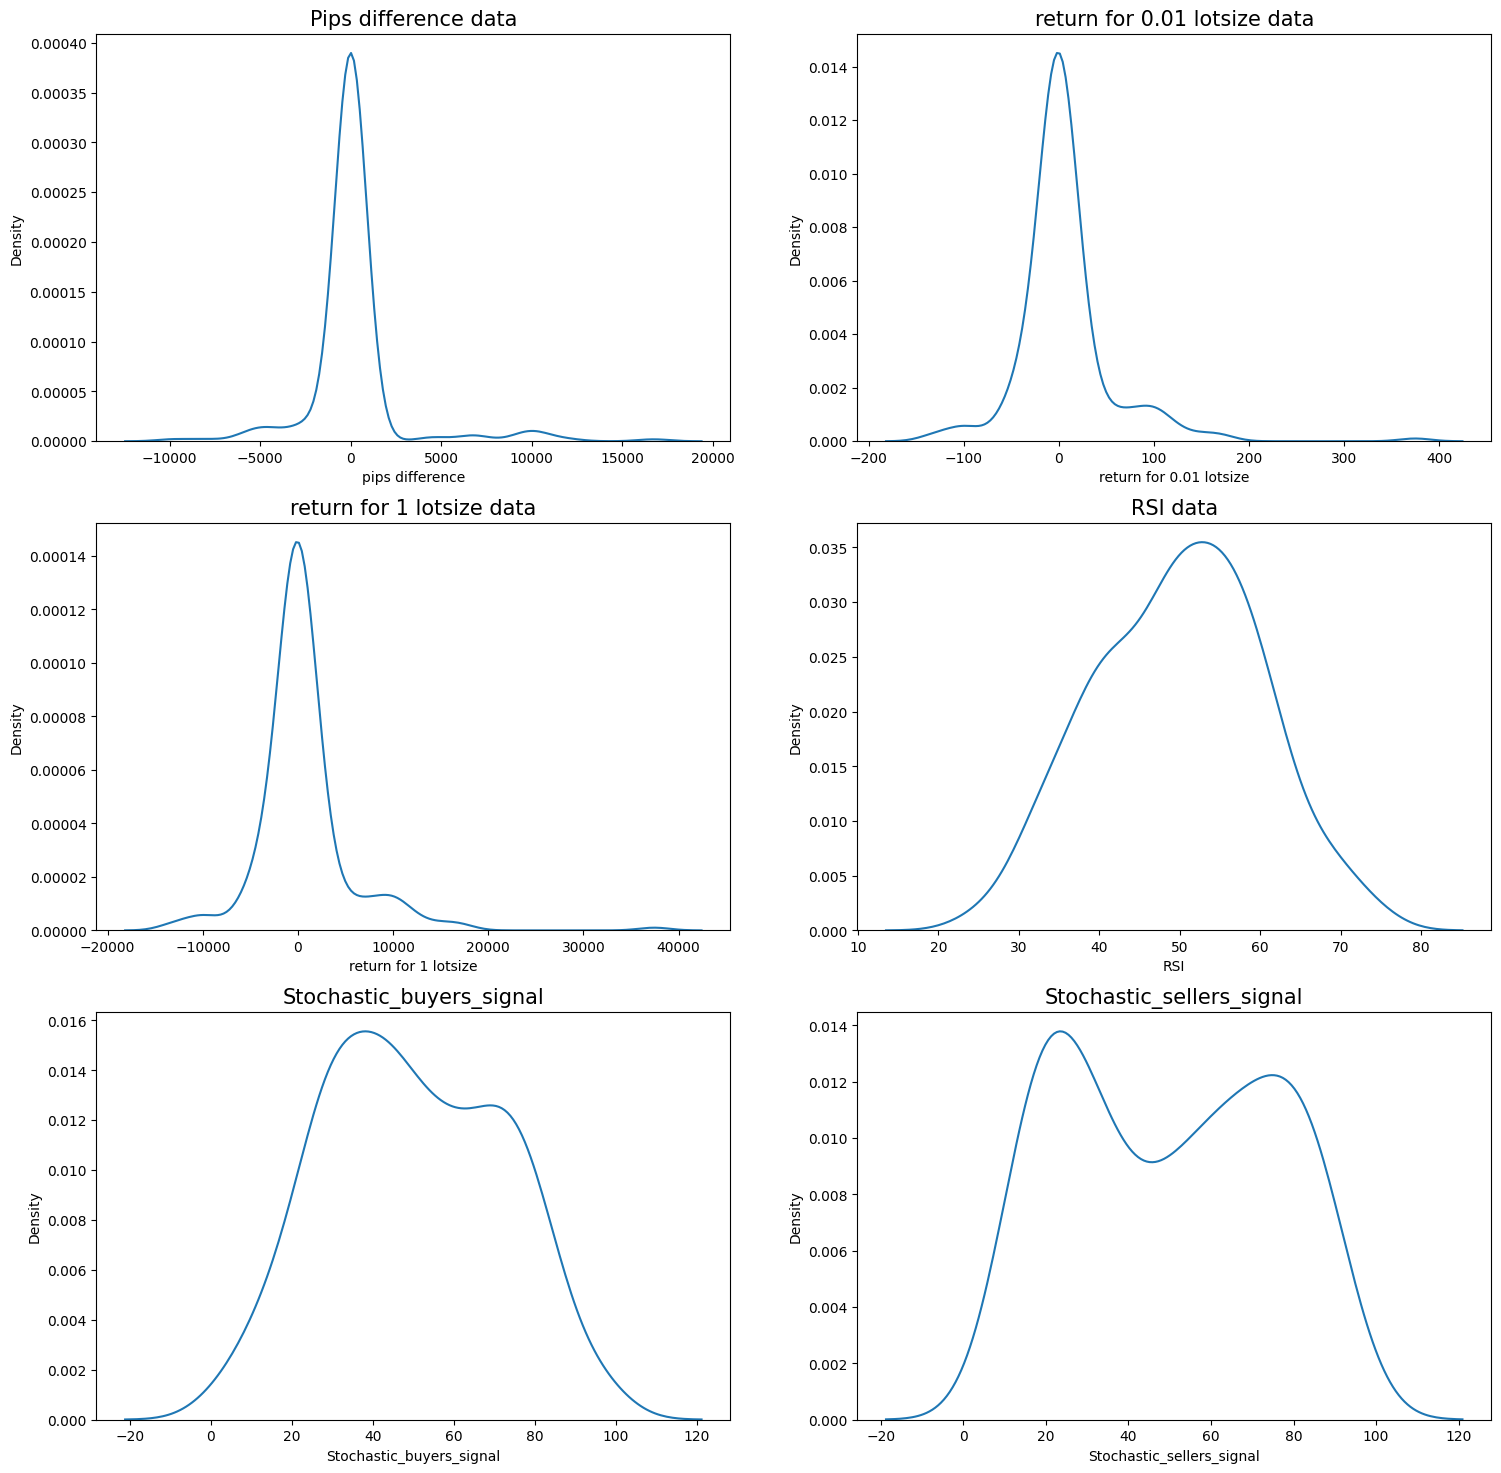

In [ ]:
plt.figure(figsize = [18,18])

plt.subplot(3,2,1)
plt.title("Pips difference data",fontsize = 15)
sns.kdeplot(data = df, x = "pips difference")

plt.subplot(3,2,2)
plt.title("return for 0.01 lotsize data",fontsize = 15)
sns.kdeplot(data = df, x = "return for 0.01 lotsize")

plt.subplot(3,2,3)
plt.title("return for 1 lotsize data",fontsize = 15)
sns.kdeplot(data = df, x = "return for 1 lotsize")

plt.subplot(3,2,4)
plt.title("RSI data",fontsize = 15)
sns.kdeplot(data = df, x = "RSI")

plt.subplot(3,2,5)
plt.title("Stochastic_buyers_signal",fontsize = 15)
sns.kdeplot(data = df, x = "Stochastic_buyers_signal")

plt.subplot(3,2,6)
plt.title("Stochastic_sellers_signal",fontsize = 15)
sns.kdeplot(data = df, x = "Stochastic_sellers_signal")

plt.show()

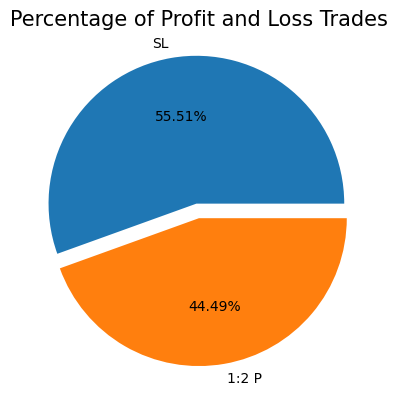

In [ ]:
plt.title("Percentage of Profit and Loss Trades",fontsize = 15)
plt.pie(
        df["Profit/SL"].value_counts(),
        labels = df["Profit/SL"].value_counts().index,
        explode = (0.1,0),
        autopct = "%.2f%%"

)
plt.show()

* **target column has two categories with nearly equal dataset size. So we can see the collected data set nearly balanced dataset. So, no need of smoting process required.**

# Target Encoding & Standard Scaling the dataset

In [ ]:
def encode(data):
  if data == "1:2 P":
    return 1
  else :
    return 0

df['Profit/SL'] = df['Profit/SL'].apply(encode)

In [ ]:
df.columns

Index(['Trade Entry Time', 'Currency Pair', '4H Trend', 'D Trend', 'W Trend',
       'Reversal/Retrace', 'R_S tf', 'R_S', 'Candlestick pattern',
       'Candlestick confirmation', 'no. of times R/S hitted', 'Trade Entry TF',
       'Buy/Sell', 'entry', 'exit', 'lot size', 'pips difference',
       'return for 0.01 lotsize', 'return for 1 lotsize', 'Profit/SL',
       'Trade Entry direction', 'Market direction', 'CPR type', 'RSI',
       'Stochastic_buyers_signal', 'Stochastic_sellers_signal', 'EMA 14',
       'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud',
       'Super Trend'],
      dtype='object')

In [ ]:
technical_analysis_cols = ['Currency Pair', '4H Trend', 'D Trend', 'W Trend','Reversal/Retrace','R_S tf', 'R_S',
                           'Candlestick pattern', 'Candlestick confirmation','no. of times R/S hitted', 'Trade Entry TF', 'Buy/Sell']
indicator_cols = ['CPR type', 'RSI', 'Stochastic_buyers_signal', 'Stochastic_sellers_signal', 'EMA 14',
                  'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud','Super Trend']
y = df["Profit/SL"]
X = df[technical_analysis_cols+indicator_cols]
X.shape

(236, 22)

In [ ]:
X[technical_analysis_cols].head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
0,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Engulfing,Instance,2.0,D,Buy
1,BTCUSD,Up,Up,Up,Reversal,D,Support,Other Bullish,Instance,4.0,4H,Buy
2,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Harami,Instance,5.0,4H,Buy
3,BTCUSD,Up,Up,Up,Reversal,D,Support,Tweezer bottom,Late,3.0,D,Buy
4,BTCUSD,Down,Up,Up,Reversal,D,Resistance,hanging man,Instance,2.0,4H,Sell


In [ ]:
X[indicator_cols].head()

,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
0,Wide,54.68345,40.552060,29.625110,Up,Down,Down,Down,Up,Down
1,Average,42.92176,45.602112,28.517125,Down,Up,Down,Down,Down,Down
2,Average,48.83411,73.791157,43.626378,just up,Down,Down,Down,Down,Down
3,Wide,51.55712,53.163940,39.770580,just up,Down,Down,Down,Up,Down
4,Average,61.89324,66.238134,48.787950,Up,Down,Up,Up,Up,Up


In [ ]:
X.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
0,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Engulfing,Instance,2.0,...,Wide,54.68345,40.552060,29.625110,Up,Down,Down,Down,Up,Down
1,BTCUSD,Up,Up,Up,Reversal,D,Support,Other Bullish,Instance,4.0,...,Average,42.92176,45.602112,28.517125,Down,Up,Down,Down,Down,Down
2,BTCUSD,Up,Up,Up,Reversal,D,Support,Bullish Harami,Instance,5.0,...,Average,48.83411,73.791157,43.626378,just up,Down,Down,Down,Down,Down
3,BTCUSD,Up,Up,Up,Reversal,D,Support,Tweezer bottom,Late,3.0,...,Wide,51.55712,53.163940,39.770580,just up,Down,Down,Down,Up,Down
4,BTCUSD,Down,Up,Up,Reversal,D,Resistance,hanging man,Instance,2.0,...,Average,61.89324,66.238134,48.787950,Up,Down,Up,Up,Up,Up


In [ ]:
X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.2,random_state=42)

print("training data size =",X_train.shape[0])
print("validation data size =",X_val.shape[0])
print("testing data size =",X_test.shape[0])


training data size = 150
validation data size = 38
testing data size = 48


In [ ]:
print(X_train.dtypes)

Currency Pair                 object
4H Trend                      object
D Trend                       object
W Trend                       object
Reversal/Retrace              object
R_S tf                        object
R_S                           object
Candlestick pattern           object
Candlestick confirmation      object
no. of times R/S hitted      float64
Trade Entry TF                object
Buy/Sell                      object
CPR type                      object
RSI                          float64
Stochastic_buyers_signal     float64
Stochastic_sellers_signal    float64
EMA 14                        object
SAR                           object
Bollinger Band                object
Ichimoku_line                 object
Ichimoku_cloud                object
Super Trend                   object
dtype: object


In [ ]:
encoding_cols = ['Currency Pair', '4H Trend', 'D Trend', 'W Trend', 'Reversal/Retrace', 'R_S tf', 'R_S', 'Candlestick pattern', 'Candlestick confirmation',
                 'Trade Entry TF', 'Buy/Sell',
                 'CPR type','EMA 14', 'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud', 'Super Trend']
encoding_cols

['Currency Pair',
 '4H Trend',
 'D Trend',
 'W Trend',
 'Reversal/Retrace',
 'R_S tf',
 'R_S',
 'Candlestick pattern',
 'Candlestick confirmation',
 'Trade Entry TF',
 'Buy/Sell',
 'CPR type',
 'EMA 14',
 'SAR',
 'Bollinger Band',
 'Ichimoku_line',
 'Ichimoku_cloud',
 'Super Trend']

In [ ]:
encoder = TargetEncoder()

for col in encoding_cols:

    # Fit on training
    X_train[col] = encoder.fit_transform(X_train[[col]], y_train)

    # Apply same encoding to val & test
    X_val[col] = encoder.transform(X_val[[col]])
    X_test[col] = encoder.transform(X_test[[col]])


In [ ]:
X_train.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
12,0.440334,0.483116,0.431041,0.465333,0.391351,0.407510,0.494203,0.510742,0.430008,2.0,...,0.446612,41.86955,31.210090,20.017991,0.407703,0.452383,0.493561,0.486719,0.45072,0.468313
23,0.440334,0.483116,0.455554,0.463152,0.391351,0.407510,0.494203,0.510742,0.430008,2.0,...,0.408891,53.25298,72.265890,61.769300,0.411848,0.454533,0.408723,0.438990,0.45569,0.468313
47,0.481272,0.483116,0.455554,0.463152,0.549571,0.488607,0.494203,0.433089,0.497787,2.0,...,0.446612,37.30032,16.364242,23.416200,0.407703,0.452383,0.493561,0.486719,0.45072,0.468313
33,0.481272,0.483116,0.431041,0.465333,0.549571,0.407510,0.494203,0.481580,0.497787,3.0,...,0.446612,56.90048,58.902895,49.757070,0.526667,0.454533,0.493561,0.486719,0.45569,0.468313
64,0.481272,0.431522,0.431041,0.419988,0.391351,0.488607,0.397582,0.416130,0.430008,4.0,...,0.408891,52.93060,55.026540,73.581590,0.411848,0.454533,0.408723,0.422257,0.45569,0.468313


In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X.columns

Index(['Currency Pair', '4H Trend', 'D Trend', 'W Trend', 'Reversal/Retrace',
       'R_S tf', 'R_S', 'Candlestick pattern', 'Candlestick confirmation',
       'no. of times R/S hitted', 'Trade Entry TF', 'Buy/Sell', 'CPR type',
       'RSI', 'Stochastic_buyers_signal', 'Stochastic_sellers_signal',
       'EMA 14', 'SAR', 'Bollinger Band', 'Ichimoku_line', 'Ichimoku_cloud',
       'Super Trend'],
      dtype='object')

# Preparing Training,validation,Testing data

In [ ]:
X_train = pd.DataFrame(X_train_scaled, columns=X.columns,index = X_train.index)
X_val   = pd.DataFrame(X_val_scaled, columns=X.columns,index = X_val.index)
X_test  = pd.DataFrame(X_test_scaled, columns=X.columns,index = X_test.index)
X_val.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
106,-0.003054,-1.084846,-1.446404,0.638780,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,...,-1.011500,1.025821,1.079891,1.397770,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835
37,0.953720,0.803012,1.700263,0.638780,1.259447,-0.920268,0.850963,1.279081,1.414214,-0.895802,...,-0.119333,0.764993,0.122270,-0.017974,1.969249,-0.886405,-1.054835,-1.077184,0.948016,-1.054835
113,-0.003054,-1.084846,1.700263,-1.845585,1.259447,-0.920268,-1.175139,-0.934193,-0.707107,-0.895802,...,-1.011500,-1.707438,-1.848574,-1.464882,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
223,1.171199,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,-0.365979,1.414214,0.920013,...,1.532591,-0.388282,-0.094618,-0.690421,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
98,0.804884,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,-0.895802,...,-0.119333,1.113456,0.233766,0.468303,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835


In [ ]:
y_val.head()

,Profit/SL
106,0
37,1
113,0
223,1
98,0


In [ ]:
# train,validataion,testing data without technical indicators
X_train_without_indicators = X_train[technical_analysis_cols]
X_val_without_indicators = X_val[technical_analysis_cols]
X_test_without_indicators = X_test[technical_analysis_cols]

# train,validataion,testing data including technical indicators (i.e.technical analyis col and indicators)
X_train_with_indicators = X_train
X_val_with_indicators = X_val
X_test_with_indicators = X_test

In [ ]:
X_train_without_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
12,-0.369303,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,0.436012,0.850963
23,-0.369303,0.803012,0.334936,0.519321,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,0.436012,0.850963
47,0.953720,0.803012,0.334936,0.519321,1.259447,1.013487,0.850963,-0.365979,1.414214,-0.895802,0.436012,0.850963
33,0.953720,0.803012,-1.446404,0.638780,1.259447,-0.920268,0.850963,0.661294,1.414214,0.012105,0.436012,0.850963
64,0.953720,-1.084846,-1.446404,-1.845585,-0.793999,1.013487,-1.175139,-0.725236,-0.707107,0.920013,-2.291277,-1.175139


In [ ]:
X_train_with_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
12,-0.369303,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,...,-0.119333,-0.758611,-0.840854,-1.176219,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
23,-0.369303,0.803012,0.334936,0.519321,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,...,-1.011500,0.365007,1.031413,0.463984,-0.503107,1.128152,-1.054835,-0.543533,0.948016,0.948016
47,0.953720,0.803012,0.334936,0.519321,1.259447,1.013487,0.850963,-0.365979,1.414214,-0.895802,...,-0.119333,-1.209624,-1.517869,-1.042720,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
33,0.953720,0.803012,-1.446404,0.638780,1.259447,-0.920268,0.850963,0.661294,1.414214,0.012105,...,-0.119333,0.725039,0.422021,-0.007917,1.969249,1.128152,0.948016,0.978620,0.948016,0.948016
64,0.953720,-1.084846,-1.446404,-1.845585,-0.793999,1.013487,-1.175139,-0.725236,-0.707107,0.920013,...,-1.011500,0.333186,0.245247,0.928030,-0.503107,1.128152,-1.054835,-1.077184,0.948016,0.948016


# Logistic model without technical indicators

In [ ]:
# training the model without technical indicators i.e. only using technical analysis information
model = LogisticRegression()
model.fit(X_train_without_indicators, y_train)

LogisticRegression()

In [ ]:
model.coef_

array([[ 0.23486643,  0.07510901, -0.02214848,  0.07404552,  0.24358329,
         0.33408929, -0.13736854,  0.64237735,  0.03692362, -0.20258013,
         0.13749906, -0.13736854]])

In [ ]:
for i in range(len(model.coef_[0])):
    print(f"{X_train.columns[i]:<25} ---> {model.coef_[0, i]:>10.6f}")


Currency Pair             --->   0.234866
4H Trend                  --->   0.075109
D Trend                   --->  -0.022148
W Trend                   --->   0.074046
Reversal/Retrace          --->   0.243583
R_S tf                    --->   0.334089
R_S                       --->  -0.137369
Candlestick pattern       --->   0.642377
Candlestick confirmation  --->   0.036924
no. of times R/S hitted   --->  -0.202580
Trade Entry TF            --->   0.137499
Buy/Sell                  --->  -0.137369


* From the weight parameters of model we can clearly observe that candlestick pattern (0.64) , R_S tf (0.33), Reversal/Retracement (0.24) & no.of times R/S hitted (-0.20) have the highest weights which impacts in prediction of target variable.
* This is realistic scenario in trading also because most trades rely on candlestick patterns, timeframe of R/S, how many times R/S hitted, and whether trade is reversal/ retracement.

In [ ]:
model.intercept_

array([-0.21009164])

In [ ]:
model.predict(X_test_without_indicators)

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 0, 1, 0])

In [ ]:
model.score(X_test_without_indicators,y_test)

0.5625

In [ ]:
def accuracy(y_true, y_pred):
  return np.sum(y_true==y_pred)/y_true.shape[0]

In [ ]:
accuracy(y_train, model.predict(X_train_without_indicators))

np.float64(0.6466666666666666)

In [ ]:
accuracy(y_val, model.predict(X_val_without_indicators))

np.float64(0.6052631578947368)

In [ ]:
train_scores = []
val_scores = []
lambda_values = []
scaler = StandardScaler()
for la in np.arange(0.01, 600.0, 20): # range of values of Lambda
  scaled_lr = make_pipeline(scaler, LogisticRegression(C=1/la))
  scaled_lr.fit(X_train_without_indicators, y_train)

  train_score = accuracy(y_train, scaled_lr.predict(X_train_without_indicators))
  val_score = accuracy(y_val, scaled_lr.predict(X_val_without_indicators))


  train_scores.append(train_score)
  val_scores.append(val_score)
  lambda_values.append(la)


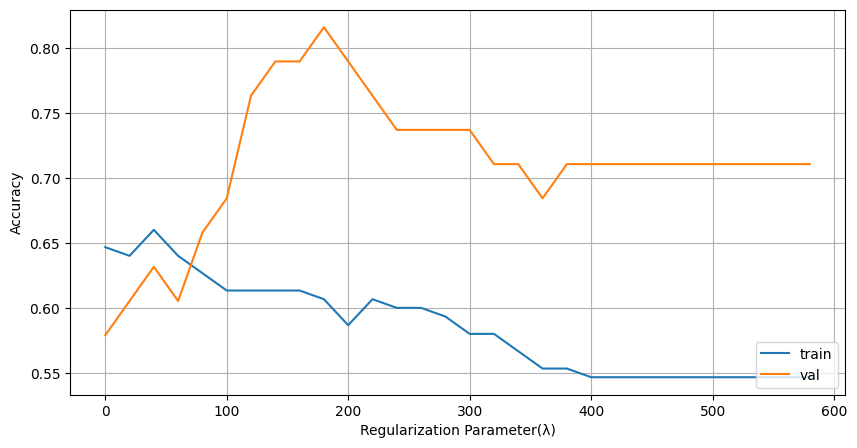

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(0.01, 600.0, 20)), train_scores, label="train")
plt.plot(list(np.arange(0.01, 600.0, 20)), val_scores, label="val")
plt.legend(loc='lower right')

plt.xlabel("Regularization Parameter(λ)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
best_index = np.argmax(val_scores)
best_lambda = lambda_values[best_index]
best_val_acc = val_scores[best_index]

print("Best λ:", best_lambda)
print("Validation Accuracy at best λ:", best_val_acc)


Best λ: 180.01
Validation Accuracy at best λ: 0.8157894736842105


In [ ]:
model = LogisticRegression(C=1/best_lambda)
model.fit(X_train_without_indicators, y_train)

LogisticRegression(C=np.float64(0.005555246930726071))

In [ ]:
model.score(X_test_without_indicators,y_test)

0.4583333333333333

In [ ]:
test_scores = []

for la in np.arange(0.01, 600.0, 20): # range of values of Lambda
  model = LogisticRegression(C=1/la)
  model.fit(X_train_without_indicators, y_train)
  test_score = model.score(X_test_without_indicators,y_test)

  test_scores.append(test_score)

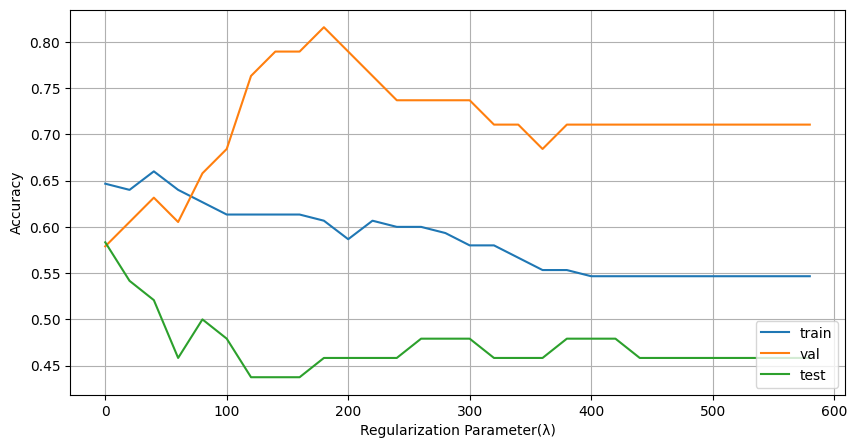

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(0.01, 600.0, 20)), train_scores, label="train")
plt.plot(list(np.arange(0.01, 600.0, 20)), val_scores, label="val")
plt.plot(list(np.arange(0.01, 600.0, 20)), test_scores, label="test")
plt.legend(loc='lower right')

plt.xlabel("Regularization Parameter(λ)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

* **models seems very underfitting as lambda increasing so, logistic regression without lambda is performing great.**

In [ ]:
model = LogisticRegression()
model.fit(X_train_without_indicators, y_train)

LogisticRegression()

In [ ]:
model.score(X_test_without_indicators, y_test)

0.5625

In [ ]:
y_pred = model.predict(X_test_without_indicators)

conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix # 2D np array

array([[15,  7],
       [14, 12]])

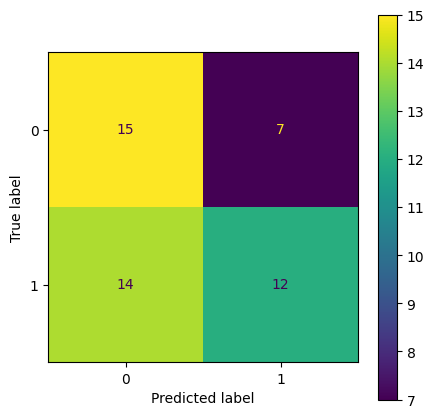

In [ ]:
# ax used here to control the size of confusion matrix
fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay(conf_matrix).plot(ax = ax)
plt.show()

In [ ]:
np.array(y_test),y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
        1, 0, 1, 0]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

recall = recall_calc(conf_matrix)
precision = precision_calc(conf_matrix)
f1 = 2* (precision*recall)/(precision+recall+1e-6)

print(f"precision :  {precision}")
print(f"recall    :  {recall}")
print(f'f1Score   :  {f1}')

precision :  0.631578947368421
recall    :  0.46153846153846156
f1Score   :  0.5333328454325451


In [ ]:
probability = model.predict_proba(X_test_without_indicators)

In [ ]:
probabilites = probability[:,1]

In [ ]:
fpr, tpr, thr = roc_curve(y_test,probabilites)

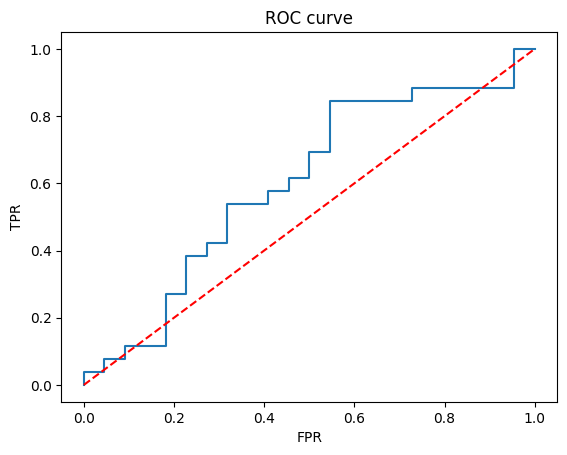

In [ ]:
plt.plot(fpr,tpr)

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

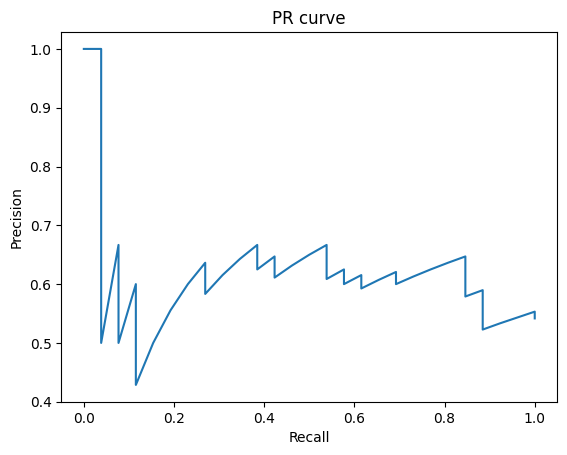

In [ ]:
precision, recall, thr = precision_recall_curve(y_test, probabilites)

plt.plot(recall, precision)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve')
plt.show()

## Performing K fold cross validation due to smaller dataset

In [ ]:
X_train_val_without_indicators = pd.concat([X_train_without_indicators,X_val_without_indicators],axis=0,ignore_index=True)
X_train_val_without_indicators.shape

(188, 12)

In [ ]:
y_train_val = pd.concat([y_train,y_val],axis=0,ignore_index=True)
y_train_val.shape

(188,)

In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []



  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # logistic regression
      k_fold_model = LogisticRegression()

      # Train on training fold
      k_fold_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = k_fold_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = k_fold_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.7067, Val Acc = 0.5526
Fold 2: Train Acc = 0.6333, Val Acc = 0.6316
Fold 3: Train Acc = 0.6600, Val Acc = 0.5526
Fold 4: Train Acc = 0.6887, Val Acc = 0.6216
Fold 5: Train Acc = 0.6424, Val Acc = 0.5946

Mean Train Acc = 0.6662251655629139 	std train Acc = 0.027682238910282642
Mean Val Acc   = 0.5906116642958749 	std val Acc   = 0.033288956834406455


(np.float64(0.6662251655629139), np.float64(0.5906116642958749))

* without k fold cross validation we got train Accuracy = 0.6466666666666666
* without k fold cross validation we got val Accuracy = 0.6052631578947368
* =======================================================================
* with k fold cross validation we got train Accuracy = 0.6662251655629139
* with k fold cross validation we got val Accuracy =  0.5906116642958749

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 0.6800, Val Acc = 0.6349
Fold 2: Train Acc = 0.6720, Val Acc = 0.5079
Fold 3: Train Acc = 0.6905, Val Acc = 0.5000

Mean Train Acc = 0.6808253968253969 	std train Acc = 0.007565419731367576
Mean Val Acc   = 0.5476190476190476 	std val Acc   = 0.06181651558490963


------ kfold = 4 splits ---------

Fold 1: Train Acc = 0.7092, Val Acc = 0.5745
Fold 2: Train Acc = 0.6667, Val Acc = 0.5745
Fold 3: Train Acc = 0.6667, Val Acc = 0.6596
Fold 4: Train Acc = 0.6809, Val Acc = 0.4894

Mean Train Acc = 0.6808510638297872 	std train Acc = 0.017372267679313345
Mean Val Acc   = 0.574468085106383 	std val Acc   = 0.06017930052651467


------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.7067, Val Acc = 0.5526
Fold 2: Train Acc = 0.6333, Val Acc = 0.6316
Fold 3: Train Acc = 0.6600, Val Acc = 0.5526
Fold 4: Train Acc = 0.6887, Val Acc = 0.6216
Fold 5: Train Acc = 0.6424, Val Acc = 0.5946

Mean Train Acc = 0.6662251655629139 	std train Acc = 

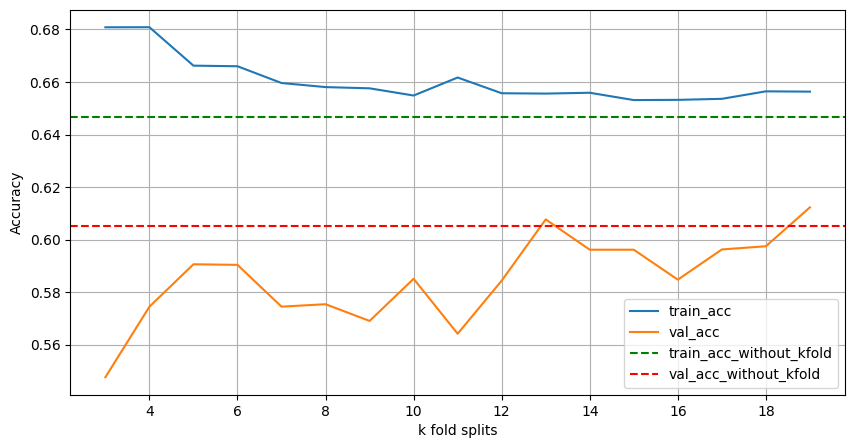

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

# Horizontal reference lines
plt.axhline(0.6466666666666666, color='green', linestyle='--', label="train_acc_without_kfold")
plt.axhline(0.6052631578947368, color='red', linestyle='--', label="val_acc_without_kfold")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

* **At 13 split we got highest validation accuracy. And also at 13th split the difference between validation accuracy and training accuracy very less.**

In [ ]:
kf = KFold(n_splits=13)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # logistic regression
    k_fold_model = LogisticRegression()

    # Train on training fold
    k_fold_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = k_fold_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = k_fold_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.6532, Val Acc = 0.6667
Fold 2: Train Acc = 0.6763, Val Acc = 0.5333
Fold 3: Train Acc = 0.6647, Val Acc = 0.4667
Fold 4: Train Acc = 0.6532, Val Acc = 0.7333
Fold 5: Train Acc = 0.6474, Val Acc = 0.6000
Fold 6: Train Acc = 0.6474, Val Acc = 0.4000
Fold 7: Train Acc = 0.6609, Val Acc = 0.7143
Fold 8: Train Acc = 0.6494, Val Acc = 0.7143
Fold 9: Train Acc = 0.6552, Val Acc = 0.7857
Fold 10: Train Acc = 0.6724, Val Acc = 0.5000
Fold 11: Train Acc = 0.6609, Val Acc = 0.5714
Fold 12: Train Acc = 0.6322, Val Acc = 0.6429
Fold 13: Train Acc = 0.6494, Val Acc = 0.5714

Mean Train Acc = 0.655588946300527 	std train Acc = 0.011171176460822293
Mean Val Acc   = 0.6076923076923078 	std val Acc   = 0.11015962066588608


In [ ]:
test_acc_using_kfold = k_fold_model.score(X_test_without_indicators,y_test)
print(f"testing Accuracy after 17 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 17 fold cross validation = 0.5833333333333334


* Before k fold cross validation we got test Accuracy = 0.562
* After k fold cross validation we got test Accuracy = 0.583
* Hence, After k fold cross validation there is improvement in accuracy of model.


## K fold cross validation model metrics & performance

In [ ]:
k_fold_y_pred = k_fold_model.predict(X_test_without_indicators)

print("confusion matrix Before K fold")
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix) # 2D np array

print("\nconfusion matrix After K fold")
k_fold_conf_matrix = confusion_matrix(y_test, k_fold_y_pred)
print(k_fold_conf_matrix) # 2D np array

confusion matrix Before K fold
[[15  7]
 [14 12]]

confusion matrix After K fold
[[17  5]
 [15 11]]


In [ ]:
def plot_conf_mat(conf_matrix, title, ax):
    ax.set_title(title, fontsize=15)
    ConfusionMatrixDisplay(conf_matrix).plot(ax=ax)
    ax.grid(False)


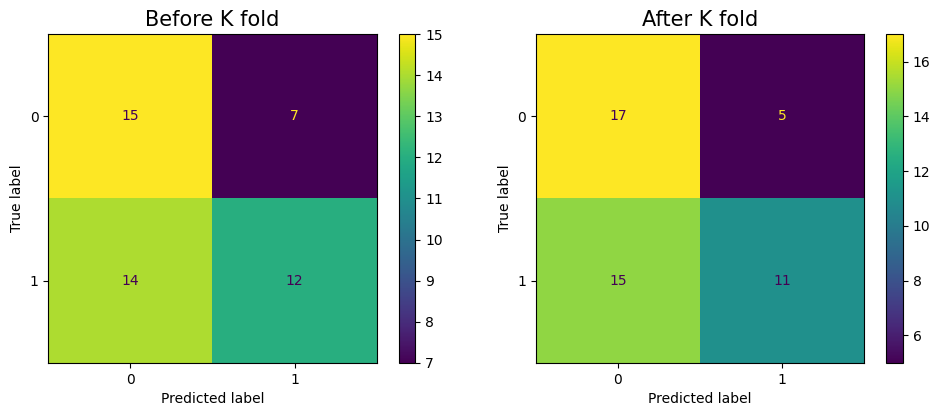

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_conf_mat(conf_matrix, "Before K fold", axes[0])
plot_conf_mat(k_fold_conf_matrix, "After K fold", axes[1])

plt.tight_layout()
plt.show()


In [ ]:
np.array(y_test),k_fold_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
        0, 0, 1, 0]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

k_fold_recall = recall_calc(k_fold_conf_matrix)
k_fold_precision = precision_calc(k_fold_conf_matrix)
k_fold_f1 = 2* (k_fold_precision*k_fold_recall)/(k_fold_precision+k_fold_recall+1e-6)

print(f"precision :  {k_fold_precision}")
print(f"recall    :  {k_fold_recall}")
print(f'f1Score   :  {k_fold_f1}')

precision :  0.6875
recall    :  0.4230769230769231
f1Score   :  0.5238090521546197


* **Before k fold cross validation :**
  * precision :  0.631
  * recall    :  0.461
  * f1Score   :  0.533

* **After K fold cross validation :**
  * precision :  0.687
  * recall    :  0.423
  * f1Score   :  0.523

## Threshold Tuning for class probabilites

In [ ]:
k_fold_probability = k_fold_model.predict_proba(X_test_without_indicators)
k_fold_probability

array([[0.51887103, 0.48112897],
       [0.84457325, 0.15542675],
       [0.51140081, 0.48859919],
       [0.58939491, 0.41060509],
       [0.65815233, 0.34184767],
       [0.52886013, 0.47113987],
       [0.55011558, 0.44988442],
       [0.4385999 , 0.5614001 ],
       [0.74492134, 0.25507866],
       [0.51071733, 0.48928267],
       [0.53878436, 0.46121564],
       [0.46841308, 0.53158692],
       [0.57873009, 0.42126991],
       [0.77338934, 0.22661066],
       [0.62882345, 0.37117655],
       [0.74492134, 0.25507866],
       [0.7986847 , 0.2013153 ],
       [0.75162334, 0.24837666],
       [0.58819559, 0.41180441],
       [0.49774319, 0.50225681],
       [0.53944893, 0.46055107],
       [0.65769549, 0.34230451],
       [0.62114269, 0.37885731],
       [0.4925914 , 0.5074086 ],
       [0.83238126, 0.16761874],
       [0.31869869, 0.68130131],
       [0.22626471, 0.77373529],
       [0.84457325, 0.15542675],
       [0.44875849, 0.55124151],
       [0.67739243, 0.32260757],
       [0.

In [ ]:
k_fold_probabilites = k_fold_probability[:,1]

In [ ]:
k_fold_fpr, k_fold_tpr, k_fold_thr = roc_curve(y_test,k_fold_probabilites)

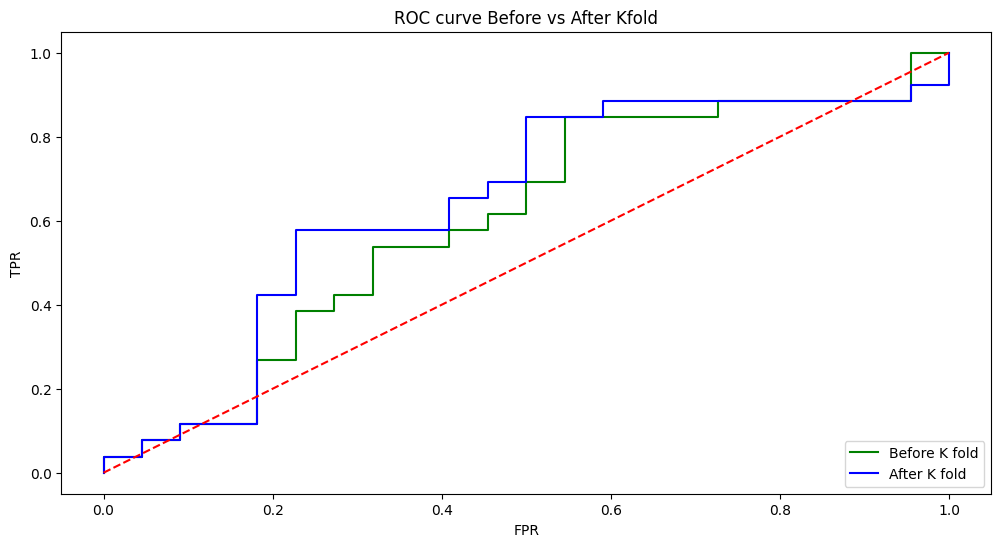

In [ ]:
plt.figure(figsize= [12,6])

plt.plot(fpr,tpr,color = "green",label = "Before K fold")
plt.plot(k_fold_fpr,k_fold_tpr,color = "blue",label = "After K fold")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve Before vs After Kfold')
plt.xlabel('FPR')
plt.ylabel('TPR')


plt.legend(loc='lower right')
plt.show()

* **AUC is improved after k fold cross validation.**

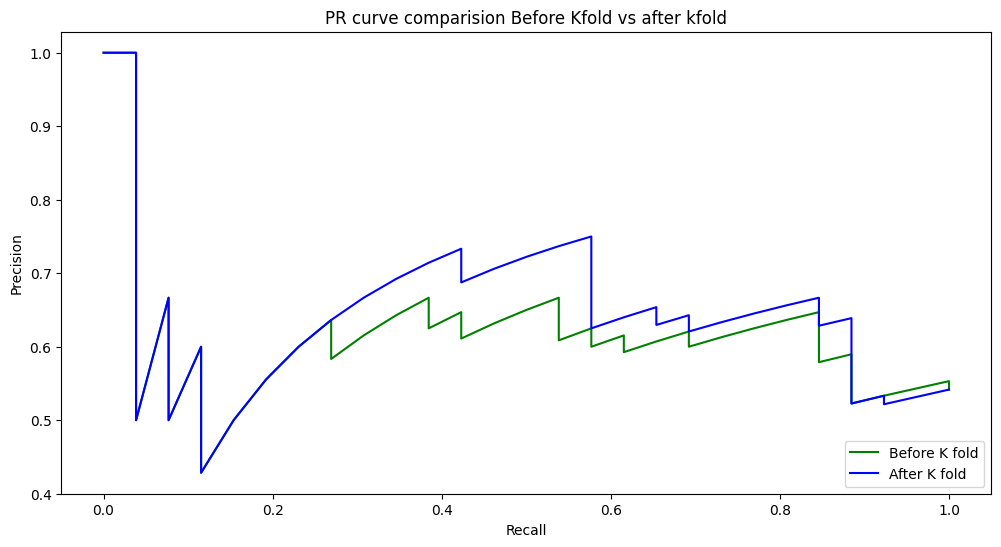

In [ ]:
k_fold_precision, k_fold_recall, k_fold_thr = precision_recall_curve(y_test, k_fold_probabilites)

plt.figure(figsize=[12,6])

plt.plot(recall, precision,color = "green",label = "Before K fold")
plt.plot(k_fold_recall, k_fold_precision,color = "blue",label = "After K fold")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve comparision Before Kfold vs after kfold')



plt.legend(loc='lower right')
plt.show()

# Logistic model with technical indicators

In [ ]:
# training the model without technical indicators i.e. only using technical analysis information
model = LogisticRegression()
model.fit(X_train_with_indicators, y_train)

LogisticRegression()

In [ ]:
X_train_with_indicators.shape

(150, 22)

In [ ]:
X_test.shape

(48, 22)

In [ ]:
model.coef_.shape

(1, 22)

In [ ]:
for i in range(len(model.coef_[0])):
    print(f"{X_train_with_indicators.columns[i]:<25} ---> {model.coef_[0, i]:>10.6f}")


Currency Pair             --->   0.280004
4H Trend                  --->   0.005398
D Trend                   --->  -0.019185
W Trend                   --->   0.039600
Reversal/Retrace          --->   0.211720
R_S tf                    --->   0.346404
R_S                       --->  -0.192484
Candlestick pattern       --->   0.751841
Candlestick confirmation  --->  -0.016095
no. of times R/S hitted   --->  -0.260084
Trade Entry TF            --->   0.167111
Buy/Sell                  --->  -0.192484
CPR type                  --->   0.202481
RSI                       --->  -0.039538
Stochastic_buyers_signal  --->  -0.080179
Stochastic_sellers_signal --->   0.525471
EMA 14                    --->   0.194609
SAR                       --->   0.223587
Bollinger Band            --->   0.814582
Ichimoku_line             --->   0.087508
Ichimoku_cloud            --->   0.163101
Super Trend               --->  -0.089466


* From the weight parameters of model we can clearly observe that following have the highest weights which impacts in prediction of target variable.
  * candlestick pattern (0.751) ,
  * R_S tf (0.34),
  * Reversal/Retracement (0.21),
  * no.of times R/S hitted (-0.26)
* In indicators
  * Bollinger Band (0.81),
  * stochastic_sellers_signal (0.52),
  * sar (0.22),
  * cpr type (0.20)
* This is realistic scenario in trading also because most trades rely on candlestick patterns, timeframe of R/S, how many times R/S hitted, and whether trade is reversal/ retracement. When coming to indicators also trades look at CPR type majorily.

In [ ]:
model.intercept_

array([-0.22084814])

In [ ]:
model.predict(X_test_with_indicators)

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 0, 1, 1])

In [ ]:
model.score(X_test_with_indicators,y_test)

0.5625

In [ ]:
def accuracy(y_true, y_pred):
  return np.sum(y_true==y_pred)/y_true.shape[0]

In [ ]:
accuracy(y_train, model.predict(X_train_with_indicators))

np.float64(0.6733333333333333)

In [ ]:
accuracy(y_val, model.predict(X_val_with_indicators))

np.float64(0.5526315789473685)

In [ ]:
train_scores = []
val_scores = []
lambda_values = []
scaler = StandardScaler()
for la in np.arange(0.01, 600.0, 20): # range of values of Lambda
  scaled_lr = make_pipeline(scaler, LogisticRegression(C=1/la))
  scaled_lr.fit(X_train_with_indicators, y_train)

  train_score = accuracy(y_train, scaled_lr.predict(X_train_with_indicators))
  val_score = accuracy(y_val, scaled_lr.predict(X_val_with_indicators))


  train_scores.append(train_score)
  val_scores.append(val_score)
  lambda_values.append(la)


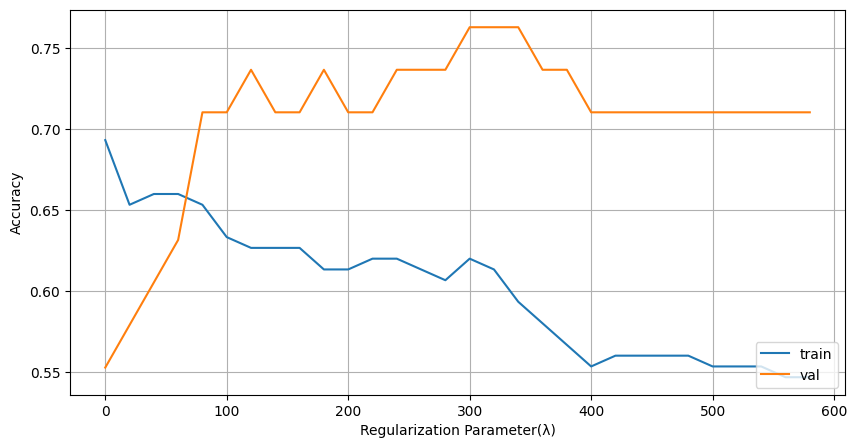

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(0.01, 600.0, 20)), train_scores, label="train")
plt.plot(list(np.arange(0.01, 600.0, 20)), val_scores, label="val")
plt.legend(loc='lower right')

plt.xlabel("Regularization Parameter(λ)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
best_index = np.argmax(val_scores)
best_lambda = lambda_values[best_index]
best_val_acc = val_scores[best_index]

print("Best λ:", best_lambda)
print("Validation Accuracy at best λ:", best_val_acc)


Best λ: 300.01
Validation Accuracy at best λ: 0.7631578947368421


In [ ]:
model = LogisticRegression(C=1/best_lambda)
model.fit(X_train_with_indicators, y_train)

LogisticRegression(C=np.float64(0.0033332222259258026))

In [ ]:
model.score(X_test_with_indicators,y_test)

0.4791666666666667

In [ ]:
test_scores = []

for la in np.arange(0.01, 600.0, 20): # range of values of Lambda
  model = LogisticRegression(C=1/la)
  model.fit(X_train_with_indicators, y_train)
  test_score = model.score(X_test_with_indicators,y_test)

  test_scores.append(test_score)

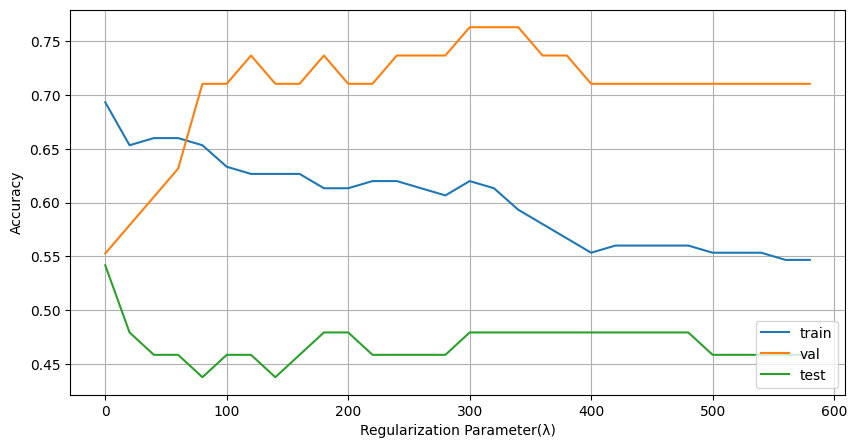

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(0.01, 600.0, 20)), train_scores, label="train")
plt.plot(list(np.arange(0.01, 600.0, 20)), val_scores, label="val")
plt.plot(list(np.arange(0.01, 600.0, 20)), test_scores, label="test")
plt.legend(loc='lower right')

plt.xlabel("Regularization Parameter(λ)")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

* models seems very underfitting as lambda increasing so, logistic regression without lambda is performing great.

In [ ]:
model = LogisticRegression()
model.fit(X_train_with_indicators, y_train)

LogisticRegression()

In [ ]:
model.score(X_test_with_indicators, y_test)

0.5625

In [ ]:
y_pred = model.predict(X_test_with_indicators)

conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix # 2D np array

array([[15,  7],
       [14, 12]])

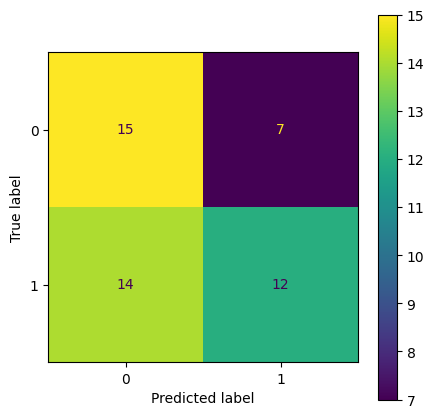

In [ ]:
# ax used here to control the size of confusion matrix
fig, ax = plt.subplots(figsize=(5,5))
ConfusionMatrixDisplay(conf_matrix).plot(ax = ax)
plt.show()

In [ ]:
np.array(y_test),y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
        0, 0, 1, 1]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

recall = recall_calc(conf_matrix)
precision = precision_calc(conf_matrix)
f1 = 2* (precision*recall)/(precision+recall+1e-6)

print(f"precision :  {precision}")
print(f"recall    :  {recall}")
print(f'f1Score   :  {f1}')

precision :  0.631578947368421
recall    :  0.46153846153846156
f1Score   :  0.5333328454325451


In [ ]:


probability = model.predict_proba(X_test_with_indicators)

In [ ]:
probabilites = probability[:,1]

In [ ]:
fpr, tpr, thr = roc_curve(y_test,probabilites)

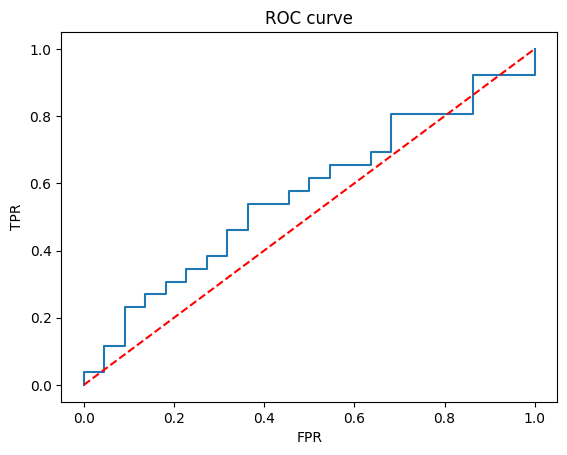

In [ ]:
plt.plot(fpr,tpr)

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

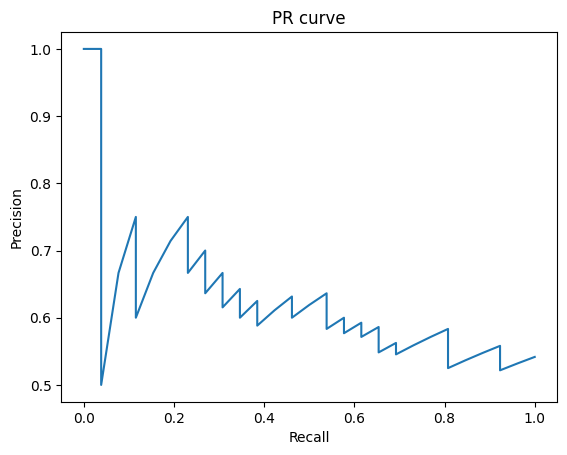

In [ ]:
precision, recall, thr = precision_recall_curve(y_test, probabilites)

plt.plot(recall, precision)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve')
plt.show()

## Performing K fold cross validation due to smaller dataset

In [ ]:
X_train_val_with_indicators = pd.concat([X_train_with_indicators,X_val_with_indicators],axis=0,ignore_index=True)
X_train_val_with_indicators.shape

(188, 22)

In [ ]:
y_train_val = pd.concat([y_train,y_val],axis=0,ignore_index=True)
y_train_val.shape

(188,)

In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []

  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # logistic regression
      k_fold_model = LogisticRegression()

      # Train on training fold
      k_fold_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = k_fold_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = k_fold_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.7000, Val Acc = 0.5526
Fold 2: Train Acc = 0.7067, Val Acc = 0.6316
Fold 3: Train Acc = 0.6533, Val Acc = 0.5263
Fold 4: Train Acc = 0.6821, Val Acc = 0.5135
Fold 5: Train Acc = 0.6821, Val Acc = 0.5405

Mean Train Acc = 0.6848476821192053 	std train Acc = 0.018513261056702906
Mean Val Acc   = 0.5529160739687056 	std val Acc   = 0.04147582264932089


(np.float64(0.6848476821192053), np.float64(0.5529160739687056))

* without k fold cross validation we got train Accuracy = 0.67333
* without k fold cross validation we got val Accuracy = 0.552631
* =======================================================================
* with k fold cross validation we got train Accuracy = 0.6662251655629139
* with k fold cross validation we got val Accuracy =  0.5906116642958749

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 0.6880, Val Acc = 0.5556
Fold 2: Train Acc = 0.6800, Val Acc = 0.5238
Fold 3: Train Acc = 0.7143, Val Acc = 0.5484

Mean Train Acc = 0.6940952380952381 	std train Acc = 0.01464562498037416
Mean Val Acc   = 0.542584058713091 	std val Acc   = 0.013594338796204036


------ kfold = 4 splits ---------

Fold 1: Train Acc = 0.6950, Val Acc = 0.5319
Fold 2: Train Acc = 0.7234, Val Acc = 0.4894
Fold 3: Train Acc = 0.6879, Val Acc = 0.6383
Fold 4: Train Acc = 0.6950, Val Acc = 0.5532

Mean Train Acc = 0.700354609929078 	std train Acc = 0.013619052744447906
Mean Val Acc   = 0.5531914893617021 	std val Acc   = 0.054244888442476456


------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.7000, Val Acc = 0.5526
Fold 2: Train Acc = 0.7067, Val Acc = 0.6316
Fold 3: Train Acc = 0.6533, Val Acc = 0.5263
Fold 4: Train Acc = 0.6821, Val Acc = 0.5135
Fold 5: Train Acc = 0.6821, Val Acc = 0.5405

Mean Train Acc = 0.6848476821192053 	std train Acc = 

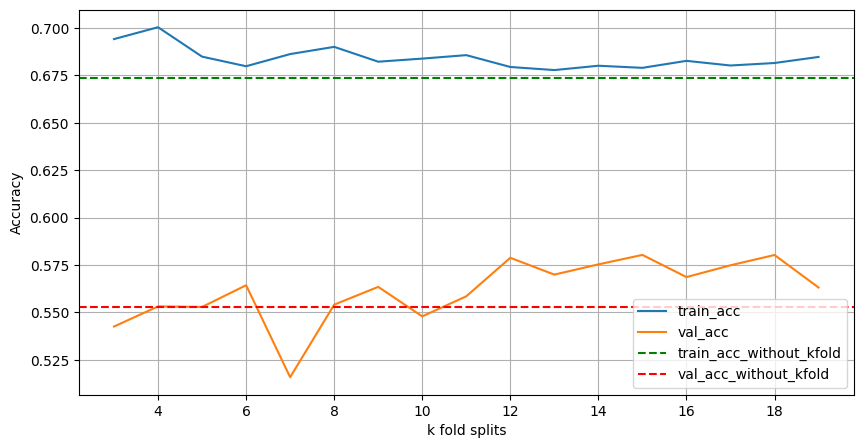

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

# Horizontal reference lines
plt.axhline(0.67333333, color='green', linestyle='--', label="train_acc_without_kfold")
plt.axhline(0.552631, color='red', linestyle='--', label="val_acc_without_kfold")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
kf = KFold(n_splits=12)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # logistic regression
    k_fold_model = LogisticRegression()

    # Train on training fold
    k_fold_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = k_fold_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = k_fold_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.6570, Val Acc = 0.6875
Fold 2: Train Acc = 0.7035, Val Acc = 0.5000
Fold 3: Train Acc = 0.7093, Val Acc = 0.4375
Fold 4: Train Acc = 0.6686, Val Acc = 0.6250
Fold 5: Train Acc = 0.6802, Val Acc = 0.6250
Fold 6: Train Acc = 0.6860, Val Acc = 0.5000
Fold 7: Train Acc = 0.6512, Val Acc = 0.7500
Fold 8: Train Acc = 0.6628, Val Acc = 0.6875
Fold 9: Train Acc = 0.6936, Val Acc = 0.4667
Fold 10: Train Acc = 0.6994, Val Acc = 0.4667
Fold 11: Train Acc = 0.6705, Val Acc = 0.7333
Fold 12: Train Acc = 0.6705, Val Acc = 0.4667

Mean Train Acc = 0.6793923914504637 	std train Acc = 0.018196202834665092
Mean Val Acc   = 0.5788194444444444 	std val Acc   = 0.11224841123872213


In [ ]:
test_acc_using_kfold = k_fold_model.score(X_test_with_indicators,y_test)
print(f"testing Accuracy after 13 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 13 fold cross validation = 0.5416666666666666


* Before k fold cross validation we got test Accuracy = 0.562
* After k fold cross validation we got test Accuracy = 0.541


## K fold cross validation model metrics & performance

In [ ]:
k_fold_y_pred = k_fold_model.predict(X_test_with_indicators)

print("confusion matrix Before K fold")
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix) # 2D np array

print("\nconfusion matrix After K fold")
k_fold_conf_matrix = confusion_matrix(y_test, k_fold_y_pred)
print(k_fold_conf_matrix) # 2D np array

confusion matrix Before K fold
[[15  7]
 [14 12]]

confusion matrix After K fold
[[15  7]
 [15 11]]


In [ ]:
def plot_conf_mat(conf_matrix, title, ax):
    ax.set_title(title, fontsize=15)
    ConfusionMatrixDisplay(conf_matrix).plot(ax=ax)
    ax.grid(False)


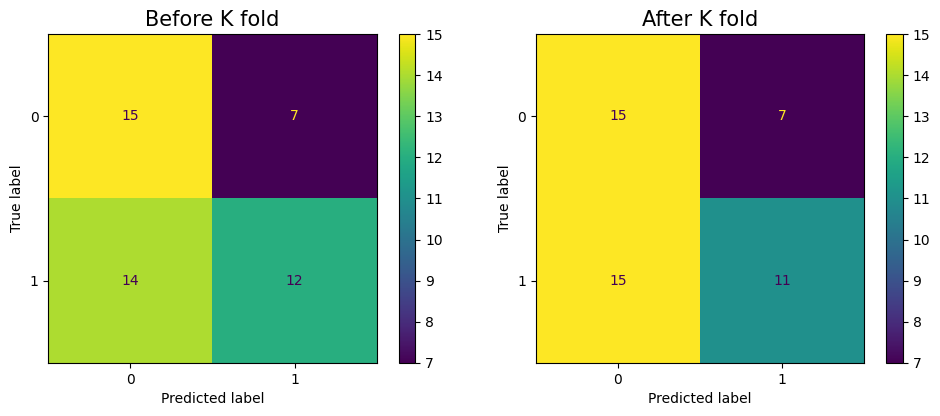

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_conf_mat(conf_matrix, "Before K fold", axes[0])
plot_conf_mat(k_fold_conf_matrix, "After K fold", axes[1])

plt.tight_layout()
plt.show()


In [ ]:
np.array(y_test),k_fold_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0,
        0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0,
        0, 0, 1, 1]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

k_fold_recall = recall_calc(k_fold_conf_matrix)
k_fold_precision = precision_calc(k_fold_conf_matrix)
k_fold_f1 = 2* (k_fold_precision*k_fold_recall)/(k_fold_precision+k_fold_recall+1e-6)

print(f"precision :  {k_fold_precision}")
print(f"recall    :  {k_fold_recall}")
print(f'f1Score   :  {k_fold_f1}')

precision :  0.6111111111111112
recall    :  0.4230769230769231
f1Score   :  0.4999995165293932


* **Before k fold cross validation :**
  * precision :  0.631
  * recall    :  0.461
  * f1Score   :  0.533


* **After K fold cross validation :**
  * precision :  0.6111
  * recall    :  0.423
  * f1Score   :  0.499

## Threshold Tuning for class probabilites

In [ ]:
k_fold_probability = k_fold_model.predict_proba(X_test_with_indicators)
k_fold_probability

array([[0.71100443, 0.28899557],
       [0.81299735, 0.18700265],
       [0.50604735, 0.49395265],
       [0.6932889 , 0.3067111 ],
       [0.60319047, 0.39680953],
       [0.69819613, 0.30180387],
       [0.53472887, 0.46527113],
       [0.37487767, 0.62512233],
       [0.66122579, 0.33877421],
       [0.73335439, 0.26664561],
       [0.71786076, 0.28213924],
       [0.49454625, 0.50545375],
       [0.36073639, 0.63926361],
       [0.77477798, 0.22522202],
       [0.36926063, 0.63073937],
       [0.62324107, 0.37675893],
       [0.8860856 , 0.1139144 ],
       [0.74984374, 0.25015626],
       [0.69704252, 0.30295748],
       [0.44068201, 0.55931799],
       [0.17134568, 0.82865432],
       [0.56808192, 0.43191808],
       [0.65582077, 0.34417923],
       [0.31153929, 0.68846071],
       [0.8847236 , 0.1152764 ],
       [0.38858022, 0.61141978],
       [0.29746277, 0.70253723],
       [0.86337849, 0.13662151],
       [0.61684322, 0.38315678],
       [0.72604246, 0.27395754],
       [0.

In [ ]:
k_fold_probabilites = k_fold_probability[:,1]

In [ ]:
k_fold_fpr, k_fold_tpr, k_fold_thr = roc_curve(y_test,k_fold_probabilites)

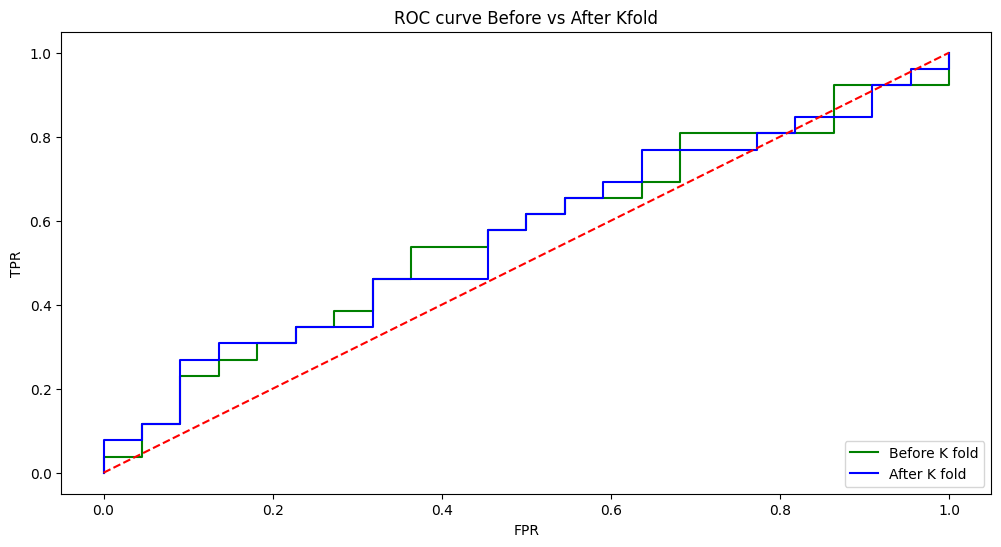

In [ ]:
plt.figure(figsize= [12,6])

plt.plot(fpr,tpr,color = "green",label = "Before K fold")
plt.plot(k_fold_fpr,k_fold_tpr,color = "blue",label = "After K fold")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve Before vs After Kfold')
plt.xlabel('FPR')
plt.ylabel('TPR')


plt.legend(loc='lower right')
plt.show()

* **AUC is improved after k fold cross validation.**

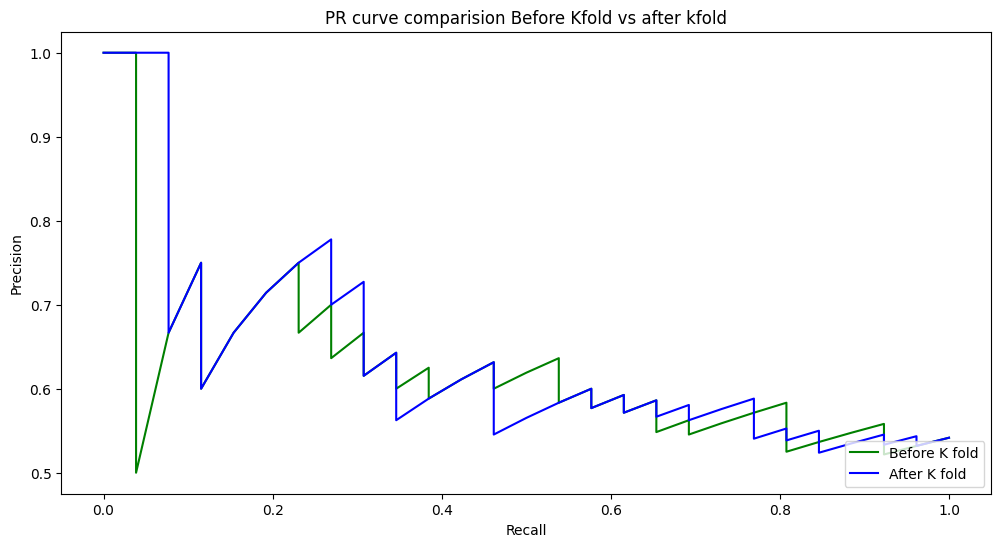

In [ ]:
k_fold_precision, k_fold_recall, k_fold_thr = precision_recall_curve(y_test, k_fold_probabilites)

plt.figure(figsize=[12,6])

plt.plot(recall, precision,color = "green",label = "Before K fold")
plt.plot(k_fold_recall, k_fold_precision,color = "blue",label = "After K fold")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve comparision Before Kfold vs after kfold')



plt.legend(loc='lower right')
plt.show()

# Random Forest Model on Without indcators dataset

In [ ]:
X_val_without_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
106,-0.003054,-1.084846,-1.446404,0.638780,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,0.436012,-1.175139
37,0.953720,0.803012,1.700263,0.638780,1.259447,-0.920268,0.850963,1.279081,1.414214,-0.895802,0.436012,0.850963
113,-0.003054,-1.084846,1.700263,-1.845585,1.259447,-0.920268,-1.175139,-0.934193,-0.707107,-0.895802,0.436012,-1.175139
223,1.171199,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,-0.365979,1.414214,0.920013,0.436012,0.850963
98,0.804884,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,-0.895802,0.436012,-1.175139


In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []



  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # random forest
      rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

      # Train on training fold
      rf_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = rf_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = rf_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.9933, Val Acc = 0.5526
Fold 2: Train Acc = 0.9867, Val Acc = 0.5526
Fold 3: Train Acc = 0.9867, Val Acc = 0.5526
Fold 4: Train Acc = 0.9934, Val Acc = 0.5405
Fold 5: Train Acc = 0.9934, Val Acc = 0.5946

Mean Train Acc = 0.9906843267108169 	std train Acc = 0.0032804453027812344
Mean Val Acc   = 0.5586059743954481 	std val Acc   = 0.01859365960274932


(np.float64(0.9906843267108169), np.float64(0.5586059743954481))

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 0.9920, Val Acc = 0.5714
Fold 2: Train Acc = 0.9920, Val Acc = 0.5238
Fold 3: Train Acc = 0.9921, Val Acc = 0.5323

Mean Train Acc = 0.992021164021164 	std train Acc = 2.993044576452659e-05
Mean Val Acc   = 0.5424987199180747 	std val Acc   = 0.020745227424355223


------ kfold = 4 splits ---------

Fold 1: Train Acc = 0.9929, Val Acc = 0.5957
Fold 2: Train Acc = 0.9858, Val Acc = 0.6170
Fold 3: Train Acc = 0.9929, Val Acc = 0.6170
Fold 4: Train Acc = 0.9929, Val Acc = 0.5957

Mean Train Acc = 0.9911347517730497 	std train Acc = 0.003071012070157588
Mean Val Acc   = 0.6063829787234043 	std val Acc   = 0.010638297872340441


------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.9933, Val Acc = 0.5526
Fold 2: Train Acc = 0.9867, Val Acc = 0.5526
Fold 3: Train Acc = 0.9867, Val Acc = 0.5526
Fold 4: Train Acc = 0.9934, Val Acc = 0.5405
Fold 5: Train Acc = 0.9934, Val Acc = 0.5946

Mean Train Acc = 0.9906843267108169 	std train Acc

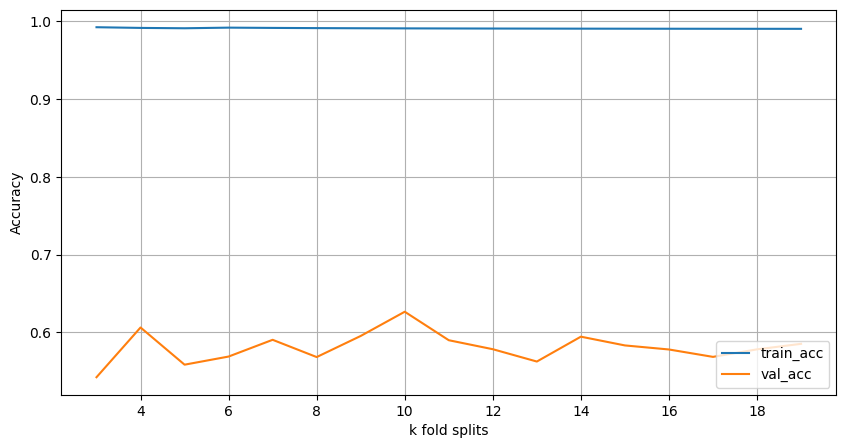

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
kf = KFold(n_splits=10)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # random forest
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train on training fold
    rf_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = rf_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = rf_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.9941, Val Acc = 0.6842
Fold 2: Train Acc = 0.9882, Val Acc = 0.5263
Fold 3: Train Acc = 0.9882, Val Acc = 0.8421
Fold 4: Train Acc = 0.9882, Val Acc = 0.4737
Fold 5: Train Acc = 0.9882, Val Acc = 0.6842
Fold 6: Train Acc = 0.9882, Val Acc = 0.7368
Fold 7: Train Acc = 0.9941, Val Acc = 0.7368
Fold 8: Train Acc = 0.9882, Val Acc = 0.5263
Fold 9: Train Acc = 0.9941, Val Acc = 0.3889
Fold 10: Train Acc = 0.9941, Val Acc = 0.6667

Mean Train Acc = 0.9905395057431257 	std train Acc = 0.0029073511601563564
Mean Val Acc   = 0.626608187134503 	std val Acc   = 0.1337894246061782


In [ ]:
test_acc_using_kfold = rf_model.score(X_test_without_indicators,y_test)
print(f"testing Accuracy after 10 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 10 fold cross validation = 0.4375


* Here the Training Acccuray = 99% , validation Accuracy = 62.66.
* So, clear overfitting occuring. so we have tune max_depth, min_sample_leaf,min_sample_splits,min_features

In [ ]:
param_grid = {
    'max_depth': [3, 4, 5, 6, None],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'min_samples_split': [2, 4, 8, 12],
    'max_features': ['sqrt', 'log2', 0.3, 0.5]
}

rf = RandomForestClassifier(n_estimators=200, random_state=42)

grid = GridSearchCV(rf, param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_without_indicators, y_train)

print(grid.best_params_)
print(grid.best_score_)


{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
0.64


In [ ]:
kf = KFold(n_splits=10)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # random forest
    rf_model = RandomForestClassifier(
    n_estimators=200,       # stable, smooth
    max_depth=5,           # prevents huge trees
    min_samples_leaf=1,    # prevents overfitting small patterns
    min_samples_split=2,   # splits need enough samples
    max_features='sqrt',   # reduces correlation between trees
    random_state=42
)

    # Train on training fold
    rf_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = rf_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = rf_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.8817, Val Acc = 0.6316
Fold 2: Train Acc = 0.8284, Val Acc = 0.4211
Fold 3: Train Acc = 0.8343, Val Acc = 0.6842
Fold 4: Train Acc = 0.8521, Val Acc = 0.5789
Fold 5: Train Acc = 0.8639, Val Acc = 0.6842
Fold 6: Train Acc = 0.8580, Val Acc = 0.6842
Fold 7: Train Acc = 0.8462, Val Acc = 0.6842
Fold 8: Train Acc = 0.8580, Val Acc = 0.4737
Fold 9: Train Acc = 0.8588, Val Acc = 0.3889
Fold 10: Train Acc = 0.8647, Val Acc = 0.7778

Mean Train Acc = 0.8546014618865299 	std train Acc = 0.014618252436062153
Mean Val Acc   = 0.6008771929824561 	std val Acc   = 0.12407621784568294


In [ ]:
test_acc_using_kfold = rf_model.score(X_test_without_indicators,y_test)
print(f"testing Accuracy after 10 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 10 fold cross validation = 0.5


## K fold cross validation model metrics & performance

In [ ]:
rf_y_pred = rf_model.predict(X_test_without_indicators)

print("\nconfusion matrix of Random Forest")
rf_conf_matrix = confusion_matrix(y_test, rf_y_pred)
print(rf_conf_matrix) # 2D np array


confusion matrix of Random Forest
[[15  7]
 [17  9]]


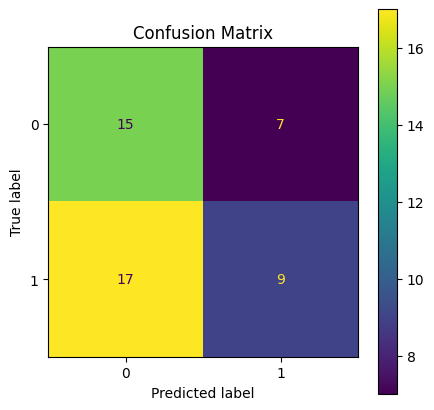

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))   # optional size
ConfusionMatrixDisplay(rf_conf_matrix).plot(ax=ax)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
np.array(y_test),rf_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
        0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0,
        0, 0, 1, 0]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

rf_recall = recall_calc(rf_conf_matrix)
rf_precision = precision_calc(rf_conf_matrix)
rf_f1 = 2* (rf_precision*rf_recall)/(rf_precision+rf_recall+1e-6)

print(f"precision :  {rf_precision}")
print(f"recall    :  {rf_recall}")
print(f'f1Score   :  {rf_f1}')

precision :  0.5625
recall    :  0.34615384615384615
f1Score   :  0.42857095691661884


## Threshold Tuning for class probabilites

In [ ]:
rf_probability = rf_model.predict_proba(X_test_without_indicators)
rf_probability

array([[0.47550026, 0.52449974],
       [0.6954035 , 0.3045965 ],
       [0.51668968, 0.48331032],
       [0.7168122 , 0.2831878 ],
       [0.72842901, 0.27157099],
       [0.57502936, 0.42497064],
       [0.45572932, 0.54427068],
       [0.53368991, 0.46631009],
       [0.56226198, 0.43773802],
       [0.72462432, 0.27537568],
       [0.43291023, 0.56708977],
       [0.50262202, 0.49737798],
       [0.60107258, 0.39892742],
       [0.71515224, 0.28484776],
       [0.41397629, 0.58602371],
       [0.56226198, 0.43773802],
       [0.67098676, 0.32901324],
       [0.85697597, 0.14302403],
       [0.41156933, 0.58843067],
       [0.47507712, 0.52492288],
       [0.47894487, 0.52105513],
       [0.65014013, 0.34985987],
       [0.6100858 , 0.3899142 ],
       [0.55687585, 0.44312415],
       [0.73954513, 0.26045487],
       [0.54106238, 0.45893762],
       [0.325003  , 0.674997  ],
       [0.6954035 , 0.3045965 ],
       [0.43675897, 0.56324103],
       [0.73489965, 0.26510035],
       [0.

In [ ]:
rf_probabilites = rf_probability[:,1]

In [ ]:
rf_fpr, rf_tpr, rf_thr = roc_curve(y_test,rf_probabilites)

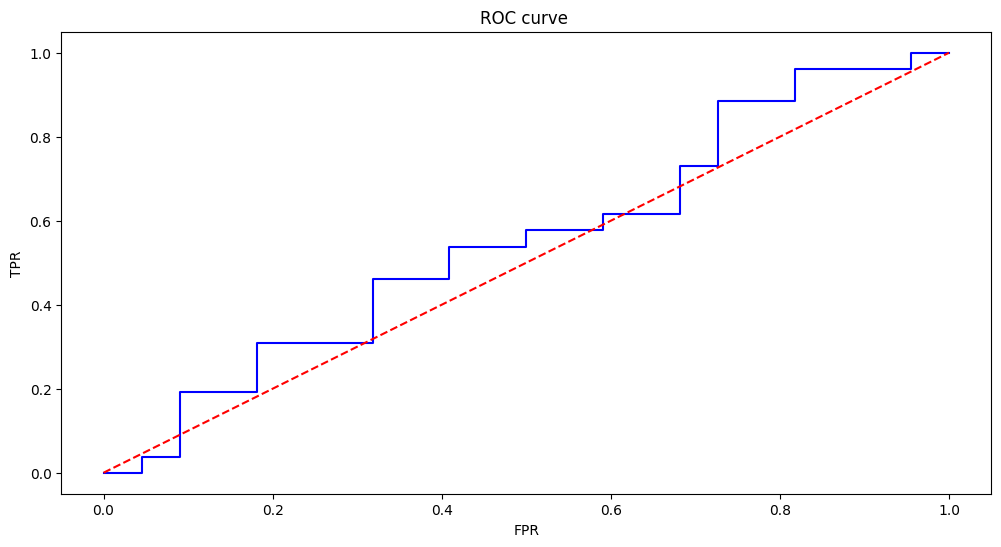

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(rf_fpr,rf_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

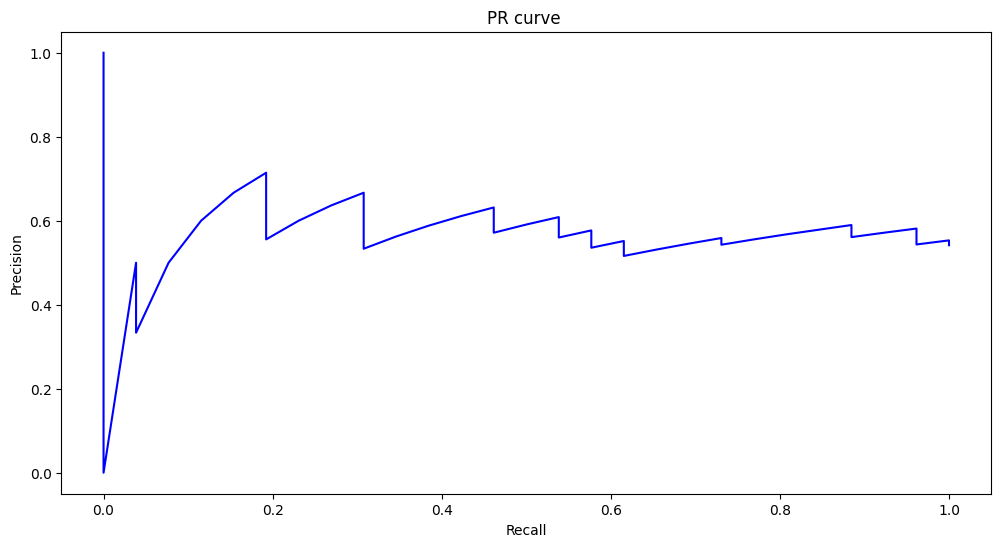

In [ ]:
rf_precision, rf_recall, rf_thr = precision_recall_curve(y_test, rf_probabilites)

plt.figure(figsize=[12,6])


plt.plot(rf_recall, rf_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# Random Forest Model on With indicators dataset

In [ ]:
X_val_with_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
106,-0.003054,-1.084846,-1.446404,0.638780,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,...,-1.011500,1.025821,1.079891,1.397770,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835
37,0.953720,0.803012,1.700263,0.638780,1.259447,-0.920268,0.850963,1.279081,1.414214,-0.895802,...,-0.119333,0.764993,0.122270,-0.017974,1.969249,-0.886405,-1.054835,-1.077184,0.948016,-1.054835
113,-0.003054,-1.084846,1.700263,-1.845585,1.259447,-0.920268,-1.175139,-0.934193,-0.707107,-0.895802,...,-1.011500,-1.707438,-1.848574,-1.464882,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
223,1.171199,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,-0.365979,1.414214,0.920013,...,1.532591,-0.388282,-0.094618,-0.690421,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
98,0.804884,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,-0.895802,...,-0.119333,1.113456,0.233766,0.468303,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835


In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []



  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # random forest
      rf2_model = RandomForestClassifier(n_estimators=100, random_state=42)

      # Train on training fold
      rf2_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = rf2_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = rf2_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5000
Fold 2: Train Acc = 1.0000, Val Acc = 0.5263
Fold 3: Train Acc = 1.0000, Val Acc = 0.6842
Fold 4: Train Acc = 1.0000, Val Acc = 0.5135
Fold 5: Train Acc = 1.0000, Val Acc = 0.5405

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5529160739687056 	std val Acc   = 0.06700990200657658


(np.float64(1.0), np.float64(0.5529160739687056))

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5714
Fold 2: Train Acc = 1.0000, Val Acc = 0.5556
Fold 3: Train Acc = 1.0000, Val Acc = 0.5161

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5477043864140638 	std val Acc   = 0.023248518243590505


------ kfold = 4 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5106
Fold 2: Train Acc = 1.0000, Val Acc = 0.5745
Fold 3: Train Acc = 1.0000, Val Acc = 0.6809
Fold 4: Train Acc = 1.0000, Val Acc = 0.4681

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5585106382978724 	std val Acc   = 0.0801410594325498


------ kfold = 5 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5000
Fold 2: Train Acc = 1.0000, Val Acc = 0.5263
Fold 3: Train Acc = 1.0000, Val Acc = 0.6842
Fold 4: Train Acc = 1.0000, Val Acc = 0.5135
Fold 5: Train Acc = 1.0000, Val Acc = 0.5405

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5529160739687056 	std val Acc   = 0.06700990200657658



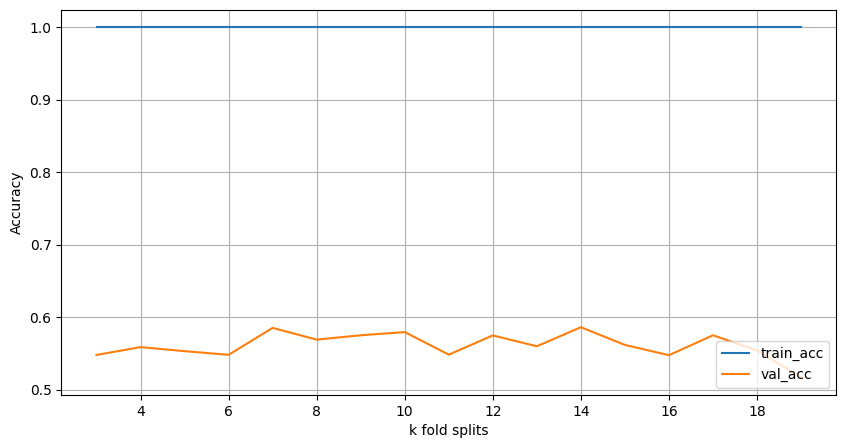

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
kf = KFold(n_splits=14)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # random forest
    rf2_model = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train on training fold
    rf2_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = rf2_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = rf2_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 1.0000, Val Acc = 0.5714
Fold 2: Train Acc = 1.0000, Val Acc = 0.5000
Fold 3: Train Acc = 1.0000, Val Acc = 0.5000
Fold 4: Train Acc = 1.0000, Val Acc = 0.5000
Fold 5: Train Acc = 1.0000, Val Acc = 0.6429
Fold 6: Train Acc = 1.0000, Val Acc = 0.6429
Fold 7: Train Acc = 1.0000, Val Acc = 0.6923
Fold 8: Train Acc = 1.0000, Val Acc = 0.6154
Fold 9: Train Acc = 1.0000, Val Acc = 0.7692
Fold 10: Train Acc = 1.0000, Val Acc = 0.6154
Fold 11: Train Acc = 1.0000, Val Acc = 0.3846
Fold 12: Train Acc = 1.0000, Val Acc = 0.5385
Fold 13: Train Acc = 1.0000, Val Acc = 0.5385
Fold 14: Train Acc = 1.0000, Val Acc = 0.6923

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5859497645211931 	std val Acc   = 0.0970435879516794


In [ ]:
test_acc_using_kfold = rf2_model.score(X_test_with_indicators,y_test)
print(f"testing Accuracy after 14 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 14 fold cross validation = 0.5833333333333334


* Here the Training Acccuray = 100% , validation Accuracy = 58.6%
* So, clear overfitting occuring. so we have tune max_depth, min_sample_leaf,min_sample_splits,min_features

In [ ]:
param_grid = {
    'max_depth': [3, 4, 5, 6, None],
    'min_samples_leaf': [1, 2, 4, 6, 8],
    'min_samples_split': [2, 4, 8, 12],
    'max_features': ['sqrt', 'log2', 0.3, 0.5]
}

rf2 = RandomForestClassifier(n_estimators=200, random_state=42)

grid2 = GridSearchCV(rf2, param_grid, cv=5, scoring='accuracy')
grid2.fit(X_train_with_indicators, y_train)

print(grid2.best_params_)
print(grid2.best_score_)


{'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2}
0.5933333333333334


In [ ]:
kf = KFold(n_splits=14)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # random forest
    rf2_model = RandomForestClassifier(
    n_estimators=200,       # stable, smooth
    max_depth=5,           # prevents huge trees
    min_samples_leaf=1,    # prevents overfitting small patterns
    min_samples_split=2,   # splits need enough samples
    max_features= 0.5,   # reduces correlation between trees
    random_state=42
)

    # Train on training fold
    rf2_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = rf2_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = rf2_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.9253, Val Acc = 0.5000
Fold 2: Train Acc = 0.9253, Val Acc = 0.5714
Fold 3: Train Acc = 0.9080, Val Acc = 0.5000
Fold 4: Train Acc = 0.9310, Val Acc = 0.5000
Fold 5: Train Acc = 0.9310, Val Acc = 0.6429
Fold 6: Train Acc = 0.9483, Val Acc = 0.6429
Fold 7: Train Acc = 0.9257, Val Acc = 0.6923
Fold 8: Train Acc = 0.9371, Val Acc = 0.6923
Fold 9: Train Acc = 0.9314, Val Acc = 0.6154
Fold 10: Train Acc = 0.9086, Val Acc = 0.6154
Fold 11: Train Acc = 0.9200, Val Acc = 0.3846
Fold 12: Train Acc = 0.9200, Val Acc = 0.4615
Fold 13: Train Acc = 0.9429, Val Acc = 0.6923
Fold 14: Train Acc = 0.9429, Val Acc = 0.6154

Mean Train Acc = 0.9283954961294862 	std train Acc = 0.01161196126593819
Mean Val Acc   = 0.5804552590266877 	std val Acc   = 0.09295780872793862


In [ ]:
test_acc_using_kfold = rf2_model.score(X_test_with_indicators,y_test)
print(f"testing Accuracy after 14 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 14 fold cross validation = 0.4791666666666667


## K fold cross validation model metrics & performance

In [ ]:
rf2_y_pred = rf2_model.predict(X_test_with_indicators)

print("\nconfusion matrix of Random Forest")
rf2_conf_matrix = confusion_matrix(y_test, rf2_y_pred)
print(rf2_conf_matrix) # 2D np array


confusion matrix of Random Forest
[[15  7]
 [18  8]]


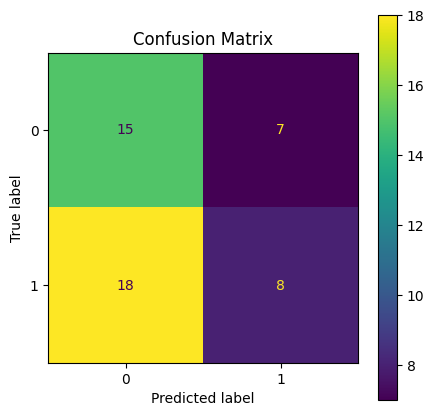

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))   # optional size
ConfusionMatrixDisplay(rf2_conf_matrix).plot(ax=ax)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
np.array(y_test),rf2_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,
        0, 0, 1, 0]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

rf2_recall = recall_calc(rf2_conf_matrix)
rf2_precision = precision_calc(rf2_conf_matrix)
rf2_f1 = 2* (rf2_precision*rf2_recall)/(rf2_precision+rf2_recall+1e-6)

print(f"precision :  {rf2_precision}")
print(f"recall    :  {rf2_recall}")
print(f'f1Score   :  {rf2_f1}')

precision :  0.5333333333333333
recall    :  0.3076923076923077
f1Score   :  0.39024343843005793


## Threshold Tuning for class probabilites

In [ ]:
rf2_probability = rf2_model.predict_proba(X_test_with_indicators)
rf2_probability

array([[0.59338268, 0.40661732],
       [0.72616413, 0.27383587],
       [0.41676892, 0.58323108],
       [0.73384609, 0.26615391],
       [0.74925747, 0.25074253],
       [0.53600248, 0.46399752],
       [0.29636368, 0.70363632],
       [0.50089515, 0.49910485],
       [0.65331492, 0.34668508],
       [0.54819678, 0.45180322],
       [0.49102707, 0.50897293],
       [0.48599931, 0.51400069],
       [0.482079  , 0.517921  ],
       [0.68267656, 0.31732344],
       [0.47357889, 0.52642111],
       [0.64136259, 0.35863741],
       [0.74192118, 0.25807882],
       [0.85597003, 0.14402997],
       [0.54671386, 0.45328614],
       [0.433713  , 0.566287  ],
       [0.59946122, 0.40053878],
       [0.66888509, 0.33111491],
       [0.54815892, 0.45184108],
       [0.62129495, 0.37870505],
       [0.78418467, 0.21581533],
       [0.60675741, 0.39324259],
       [0.35205414, 0.64794586],
       [0.53668012, 0.46331988],
       [0.58656244, 0.41343756],
       [0.67593956, 0.32406044],
       [0.

In [ ]:
rf2_probabilites = rf2_probability[:,1]

In [ ]:
rf2_fpr, rf2_tpr, rf2_thr = roc_curve(y_test,rf2_probabilites)

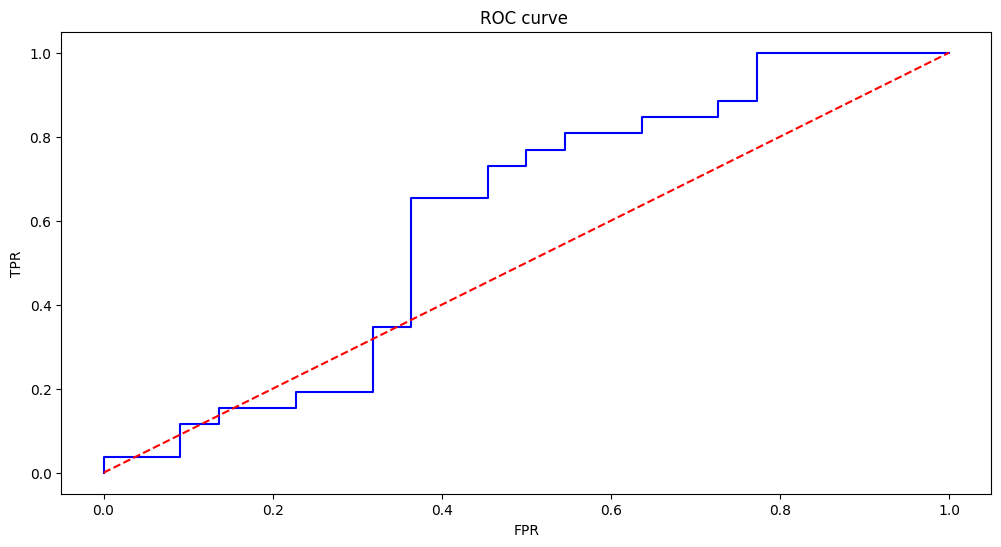

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(rf2_fpr,rf2_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

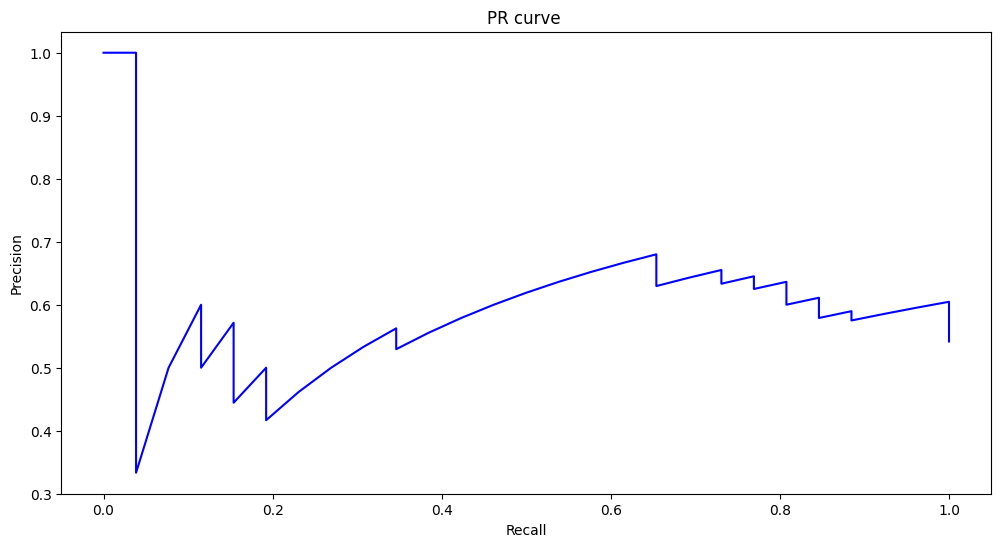

In [ ]:
rf2_precision, rf2_recall, rf2_thr = precision_recall_curve(y_test, rf2_probabilites)

plt.figure(figsize=[12,6])


plt.plot(rf2_recall, rf2_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# KNN Model Training on dataset without indicators

In [ ]:
X_train_without_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
12,-0.369303,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,0.436012,0.850963
23,-0.369303,0.803012,0.334936,0.519321,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,0.436012,0.850963
47,0.953720,0.803012,0.334936,0.519321,1.259447,1.013487,0.850963,-0.365979,1.414214,-0.895802,0.436012,0.850963
33,0.953720,0.803012,-1.446404,0.638780,1.259447,-0.920268,0.850963,0.661294,1.414214,0.012105,0.436012,0.850963
64,0.953720,-1.084846,-1.446404,-1.845585,-0.793999,1.013487,-1.175139,-0.725236,-0.707107,0.920013,-2.291277,-1.175139


In [ ]:
knn_val_scores = []
for neighbor in range(1,10,1):
  knn = KNeighborsClassifier(n_neighbors = neighbor,metric='euclidean')

  knn.fit(X_train_without_indicators, y_train)

  val_score = knn.score(X_val_without_indicators, y_val)
  knn_val_scores.append(val_score)


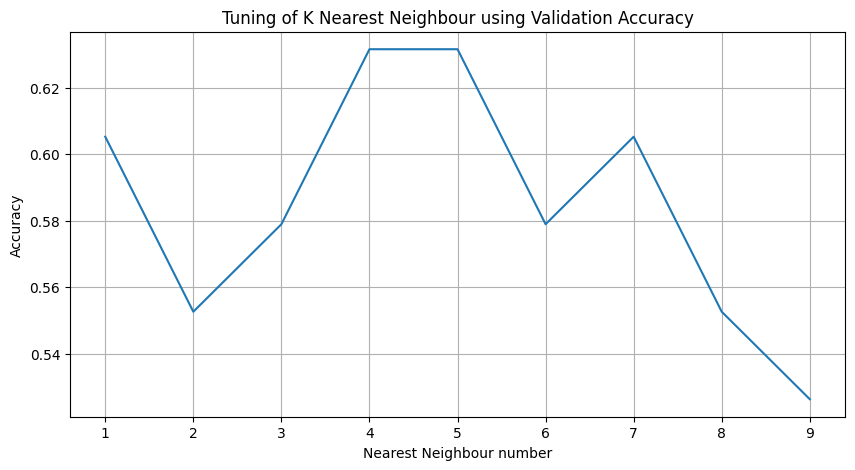

In [ ]:
plt.figure(figsize=(10,5))

plt.title("Tuning of K Nearest Neighbour using Validation Accuracy")
plt.plot(list(np.arange(1, 10, 1)), knn_val_scores)


plt.xlabel("Nearest Neighbour number")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

* **For Nearest Neighbour = 4 & 5, I got highest validation accuracy so i go with 5 nearest neighbour because it's odd number which removes tie of majority voting for knn.**

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors = 5 ,metric='euclidean')
knn_model.fit(X_train_without_indicators, y_train)

knn_model.score(X_test_without_indicators, y_test)

0.6458333333333334

In [ ]:
knn_y_pred = knn_model.predict(X_test_without_indicators)
print(classification_report(y_test, knn_y_pred))

              precision    recall  f1-score   support

           0       0.62      0.59      0.60        22
           1       0.67      0.69      0.68        26

    accuracy                           0.65        48
   macro avg       0.64      0.64      0.64        48
weighted avg       0.64      0.65      0.65        48



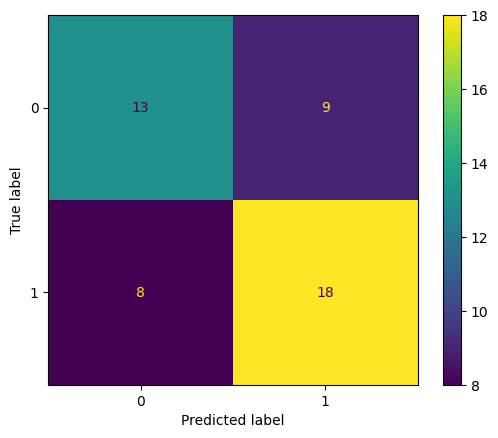

In [ ]:
cm = confusion_matrix(y_test, knn_y_pred)

ConfusionMatrixDisplay(cm).plot()
plt.show()

## Threshold Tuning for class probabilites

In [ ]:
knn_probability = knn_model.predict_proba(X_test_without_indicators)
knn_probability

array([[0.4, 0.6],
       [0.6, 0.4],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.6, 0.4],
       [0.8, 0.2],
       [0.2, 0.8],
       [0.4, 0.6],
       [0.8, 0.2],
       [0.8, 0.2],
       [0.2, 0.8],
       [0.4, 0.6],
       [0.6, 0.4],
       [0.6, 0.4],
       [0.4, 0.6],
       [0.8, 0.2],
       [0.4, 0.6],
       [1. , 0. ],
       [0.4, 0.6],
       [0.6, 0.4],
       [0.4, 0.6],
       [0.4, 0.6],
       [0.8, 0.2],
       [0.4, 0.6],
       [0.6, 0.4],
       [0.6, 0.4],
       [0.2, 0.8],
       [0.6, 0.4],
       [0.4, 0.6],
       [1. , 0. ],
       [0.8, 0.2],
       [0.2, 0.8],
       [0.8, 0.2],
       [0.6, 0.4],
       [0.4, 0.6],
       [0.2, 0.8],
       [0. , 1. ],
       [0.4, 0.6],
       [0.2, 0.8],
       [0.4, 0.6],
       [0.6, 0.4],
       [0.8, 0.2],
       [0.2, 0.8],
       [0.2, 0.8],
       [0.8, 0.2],
       [0.2, 0.8],
       [0. , 1. ],
       [0. , 1. ]])

In [ ]:
knn_probabilites = knn_probability[:,1]

In [ ]:
knn_fpr, knn_tpr, knn_thr = roc_curve(y_test,knn_probabilites)

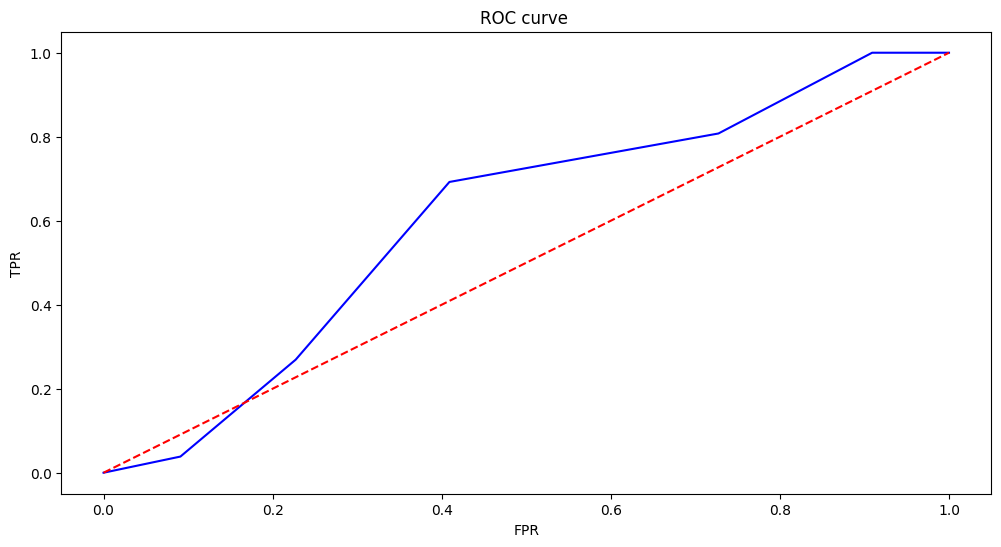

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(knn_fpr,knn_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

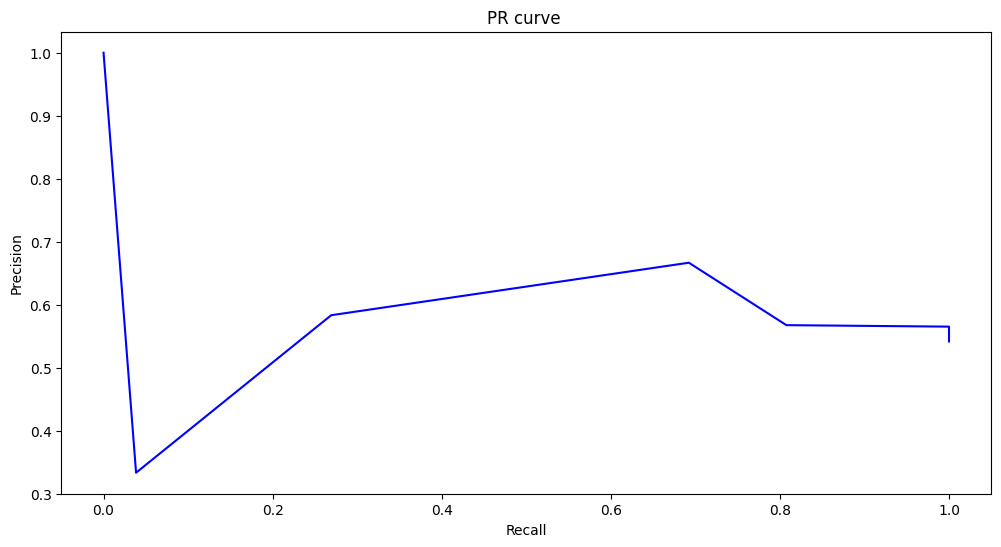

In [ ]:
knn_precision, knn_recall, knn_thr = precision_recall_curve(y_test, knn_probabilites)

plt.figure(figsize=[12,6])


plt.plot(knn_recall, knn_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# KNN Model Training on dataset with indicators

In [ ]:
X_train_with_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
12,-0.369303,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,...,-0.119333,-0.758611,-0.840854,-1.176219,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
23,-0.369303,0.803012,0.334936,0.519321,-0.793999,-0.920268,0.850963,1.279081,-0.707107,-0.895802,...,-1.011500,0.365007,1.031413,0.463984,-0.503107,1.128152,-1.054835,-0.543533,0.948016,0.948016
47,0.953720,0.803012,0.334936,0.519321,1.259447,1.013487,0.850963,-0.365979,1.414214,-0.895802,...,-0.119333,-1.209624,-1.517869,-1.042720,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
33,0.953720,0.803012,-1.446404,0.638780,1.259447,-0.920268,0.850963,0.661294,1.414214,0.012105,...,-0.119333,0.725039,0.422021,-0.007917,1.969249,1.128152,0.948016,0.978620,0.948016,0.948016
64,0.953720,-1.084846,-1.446404,-1.845585,-0.793999,1.013487,-1.175139,-0.725236,-0.707107,0.920013,...,-1.011500,0.333186,0.245247,0.928030,-0.503107,1.128152,-1.054835,-1.077184,0.948016,0.948016


In [ ]:
knn_val_scores = []
for neighbor in range(1,10,1):
  knn = KNeighborsClassifier(n_neighbors = neighbor,metric='euclidean')

  knn.fit(X_train_with_indicators, y_train)

  val_score = knn.score(X_val_with_indicators, y_val)
  knn_val_scores.append(val_score)


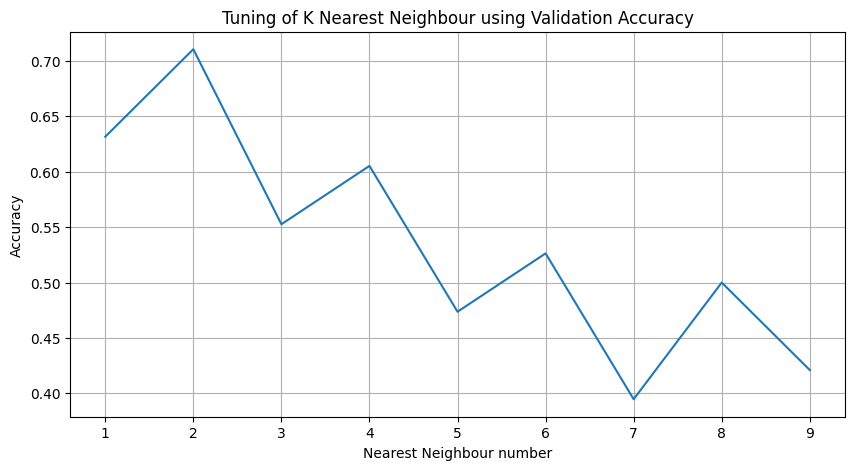

In [ ]:
plt.figure(figsize=(10,5))

plt.title("Tuning of K Nearest Neighbour using Validation Accuracy")
plt.plot(list(np.arange(1, 10, 1)), knn_val_scores)


plt.xlabel("Nearest Neighbour number")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

* **For Nearest Neighbour = 2,1,3,4 , I got highest validation accuracy.**
* **But it's even also with 4 , suppose if i pick 1 outliers effect happens.so, i finally go with 3 nearest neighbour because it's odd number which removes tie of majority voting for knn.**

In [ ]:
knn2_model = KNeighborsClassifier(n_neighbors = 3 ,metric='euclidean')
knn2_model.fit(X_train_with_indicators, y_train)

knn2_model.score(X_test_with_indicators, y_test)

0.5833333333333334

In [ ]:
knn2_y_pred = knn2_model.predict(X_test_with_indicators)
print(classification_report(y_test, knn2_y_pred))

              precision    recall  f1-score   support

           0       0.54      0.64      0.58        22
           1       0.64      0.54      0.58        26

    accuracy                           0.58        48
   macro avg       0.59      0.59      0.58        48
weighted avg       0.59      0.58      0.58        48



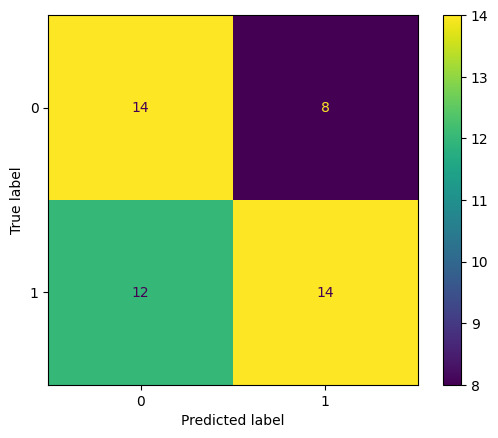

In [ ]:
cm = confusion_matrix(y_test, knn2_y_pred)

ConfusionMatrixDisplay(cm).plot()
plt.show()

## Threshold Tuning for class probabilites

In [ ]:
knn2_probability = knn2_model.predict_proba(X_test_with_indicators)
knn2_probability

array([[1.        , 0.        ],
       [0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.66666667, 0.33333333],
       [0.        , 1.        ],
       [0.66666667, 0.33333333],
       [0.66666667, 0.33333333],
       [1.        , 0.        ],
       [0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [0.66666667, 0.33333333],
       [0.66666667, 0.33333333],
       [0.66666667, 0.33333333],
       [1.        , 0.        ],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [0.33333333, 0.66666667],
       [0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [0.33333333, 0.66666667],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [0.33333333, 0.66666667],
       [0.66666667, 0.33333333],
       [0.33333333, 0.66666667],
       [1.        , 0.        ],
       [0.

In [ ]:
knn2_probabilites = knn2_probability[:,1]

In [ ]:
knn2_fpr, knn2_tpr, knn2_thr = roc_curve(y_test,knn2_probabilites)

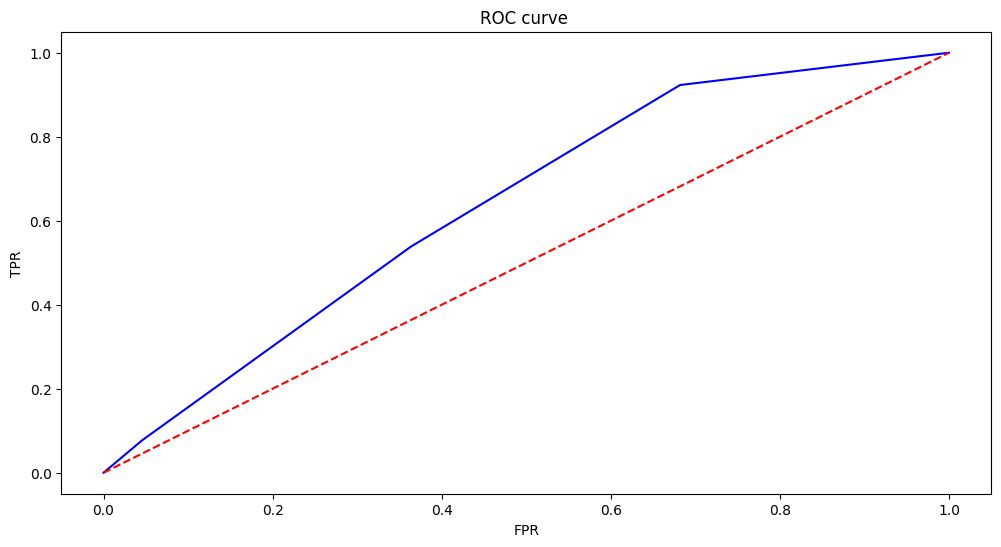

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(knn2_fpr,knn2_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

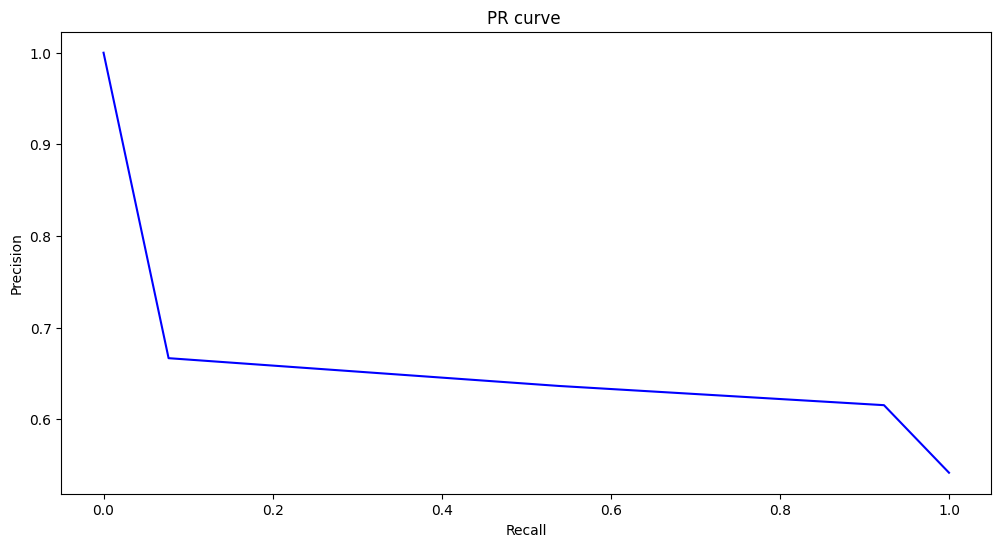

In [ ]:
knn2_precision, knn2_recall, knn2_thr = precision_recall_curve(y_test, knn2_probabilites)

plt.figure(figsize=[12,6])


plt.plot(knn2_recall, knn2_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# Decision Tree Classifier on Without Indicators dataset

In [ ]:
X_val_without_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
106,-0.003054,-1.084846,-1.446404,0.638780,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,0.436012,-1.175139
37,0.953720,0.803012,1.700263,0.638780,1.259447,-0.920268,0.850963,1.279081,1.414214,-0.895802,0.436012,0.850963
113,-0.003054,-1.084846,1.700263,-1.845585,1.259447,-0.920268,-1.175139,-0.934193,-0.707107,-0.895802,0.436012,-1.175139
223,1.171199,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,-0.365979,1.414214,0.920013,0.436012,0.850963
98,0.804884,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,-0.895802,0.436012,-1.175139


In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_without_indicators, y_train)

dt_y_train_pred = dt_model.predict(X_train_without_indicators)
dt_y_test_pred = dt_model.predict(X_test_without_indicators)

print("=== Baseline Decision Tree ===")
print("Train Accuracy:", accuracy_score(y_train,dt_y_train_pred))
print("Test  Accuracy:", accuracy_score(y_test,dt_y_test_pred))
print("Classification Report (test):")
print(classification_report(y_test,dt_y_test_pred))
print("Confusion Matrix (test):\n",confusion_matrix(y_test,dt_y_test_pred))

=== Baseline Decision Tree ===
Train Accuracy: 0.9933333333333333
Test  Accuracy: 0.5
Classification Report (test):
              precision    recall  f1-score   support

           0       0.45      0.45      0.45        22
           1       0.54      0.54      0.54        26

    accuracy                           0.50        48
   macro avg       0.50      0.50      0.50        48
weighted avg       0.50      0.50      0.50        48

Confusion Matrix (test):
 [[10 12]
 [12 14]]


In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []



  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # decision tree
      dt_model = DecisionTreeClassifier(random_state=42)

      # Train on training fold
      dt_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = dt_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = dt_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.9933, Val Acc = 0.5263
Fold 2: Train Acc = 0.9867, Val Acc = 0.4474
Fold 3: Train Acc = 0.9867, Val Acc = 0.5526
Fold 4: Train Acc = 0.9934, Val Acc = 0.4595
Fold 5: Train Acc = 0.9934, Val Acc = 0.5946

Mean Train Acc = 0.9906843267108169 	std train Acc = 0.0032804453027812344
Mean Val Acc   = 0.5160739687055476 	std val Acc   = 0.055735980093131424


(np.float64(0.9906843267108169), np.float64(0.5160739687055476))

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 0.9920, Val Acc = 0.5238
Fold 2: Train Acc = 0.9920, Val Acc = 0.5397
Fold 3: Train Acc = 0.9921, Val Acc = 0.5806

Mean Train Acc = 0.992021164021164 	std train Acc = 2.993044576452659e-05
Mean Val Acc   = 0.5480457415941288 	std val Acc   = 0.023944794585639414


------ kfold = 4 splits ---------

Fold 1: Train Acc = 0.9929, Val Acc = 0.4894
Fold 2: Train Acc = 0.9858, Val Acc = 0.4894
Fold 3: Train Acc = 0.9929, Val Acc = 0.5957
Fold 4: Train Acc = 0.9929, Val Acc = 0.5319

Mean Train Acc = 0.9911347517730497 	std train Acc = 0.003071012070157588
Mean Val Acc   = 0.526595744680851 	std val Acc   = 0.04353911048868324


------ kfold = 5 splits ---------

Fold 1: Train Acc = 0.9933, Val Acc = 0.5263
Fold 2: Train Acc = 0.9867, Val Acc = 0.4474
Fold 3: Train Acc = 0.9867, Val Acc = 0.5526
Fold 4: Train Acc = 0.9934, Val Acc = 0.4595
Fold 5: Train Acc = 0.9934, Val Acc = 0.5946

Mean Train Acc = 0.9906843267108169 	std train Acc =

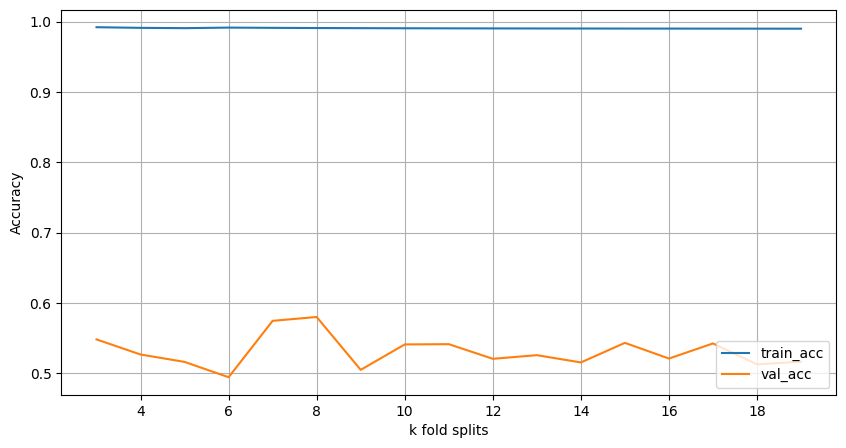

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
kf = KFold(n_splits=7)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # decision tree
    dt_model = DecisionTreeClassifier(random_state=42)

    # Train on training fold
    dt_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = dt_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = dt_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.9938, Val Acc = 0.5556
Fold 2: Train Acc = 0.9876, Val Acc = 0.5556
Fold 3: Train Acc = 0.9876, Val Acc = 0.5556
Fold 4: Train Acc = 0.9876, Val Acc = 0.5185
Fold 5: Train Acc = 0.9938, Val Acc = 0.5926
Fold 6: Train Acc = 0.9938, Val Acc = 0.6667
Fold 7: Train Acc = 0.9938, Val Acc = 0.5769

Mean Train Acc = 0.9911323627679735 	std train Acc = 0.0030785060163858974
Mean Val Acc   = 0.5744810744810744 	std val Acc   = 0.04315835846954733


In [ ]:
test_acc_using_kfold = dt_model.score(X_test_without_indicators,y_test)
print(f"testing Accuracy after 7 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 7 fold cross validation = 0.375


* Here the Training Acccuray = 99% , validation Accuracy = 57.44.
* So, clear overfitting occuring. so we have tune criterion, max_depth, min_sample_leaf,min_sample_splits,max_features,splitter

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'splitter': ['best', 'random']
}

dt = DecisionTreeClassifier(random_state=42)

grid = GridSearchCV(dt, param_grid, cv=7, scoring='accuracy',n_jobs=-1,verbose=1,refit=True)
grid.fit(X_train_without_indicators, y_train)

print(grid.best_params_)
print(grid.best_score_)


Fitting 7 folds for each of 1440 candidates, totalling 10080 fits
{'criterion': 'entropy', 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}
0.6654298082869511


In [ ]:
kf = KFold(n_splits=7)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_without_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_without_indicators.iloc[train_index], X_train_val_without_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # decision tree
    dt_model = grid.best_estimator_

    # Train on training fold
    dt_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = dt_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = dt_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.7267, Val Acc = 0.6667
Fold 2: Train Acc = 0.7081, Val Acc = 0.4444
Fold 3: Train Acc = 0.7453, Val Acc = 0.5926
Fold 4: Train Acc = 0.6957, Val Acc = 0.7037
Fold 5: Train Acc = 0.6832, Val Acc = 0.6667
Fold 6: Train Acc = 0.7391, Val Acc = 0.7407
Fold 7: Train Acc = 0.7222, Val Acc = 0.5769

Mean Train Acc = 0.7171941240264221 	std train Acc = 0.02101046307550927
Mean Val Acc   = 0.6273911273911273 	std val Acc   = 0.09179505982980561


In [ ]:
test_acc_using_kfold = dt_model.score(X_test_without_indicators,y_test)
print(f"testing Accuracy after 7 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 7 fold cross validation = 0.6041666666666666


## K fold cross validation model metrics & performance

In [ ]:
dt_y_pred = dt_model.predict(X_test_without_indicators)

print("\nconfusion matrix of Random Forest")
dt_conf_matrix = confusion_matrix(y_test, dt_y_pred)
print(dt_conf_matrix) # 2D np array


confusion matrix of Random Forest
[[16  6]
 [13 13]]


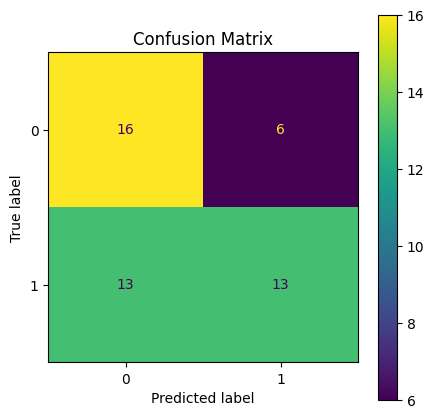

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))   # optional size
ConfusionMatrixDisplay(dt_conf_matrix).plot(ax=ax)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
np.array(y_test),dt_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0,
        0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
        0, 0, 1, 0]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

dt_recall = recall_calc(dt_conf_matrix)
dt_precision = precision_calc(dt_conf_matrix)
dt_f1 = 2* (dt_precision*dt_recall)/(dt_precision+dt_recall+1e-6)

print(f"precision :  {rf_precision}")
print(f"recall    :  {rf_recall}")
print(f'f1Score   :  {rf_f1}')

precision :  [0.54166667 0.55319149 0.54347826 0.55555556 0.56818182 0.58139535
 0.57142857 0.56097561 0.575      0.58974359 0.56756757 0.55555556
 0.54285714 0.55882353 0.54545455 0.53125    0.51612903 0.53333333
 0.55172414 0.53571429 0.55555556 0.57692308 0.56       0.60869565
 0.59090909 0.57142857 0.6        0.63157895 0.61111111 0.58823529
 0.5625     0.53333333 0.57142857 0.61538462 0.66666667 0.63636364
 0.6        0.55555556 0.625      0.71428571 0.66666667 0.6
 0.5        0.33333333 0.5        0.         1.        ]
recall    :  [1.         1.         0.96153846 0.96153846 0.96153846 0.96153846
 0.92307692 0.88461538 0.88461538 0.88461538 0.80769231 0.76923077
 0.73076923 0.73076923 0.69230769 0.65384615 0.61538462 0.61538462
 0.61538462 0.57692308 0.57692308 0.57692308 0.53846154 0.53846154
 0.5        0.46153846 0.46153846 0.46153846 0.42307692 0.38461538
 0.34615385 0.30769231 0.30769231 0.30769231 0.30769231 0.26923077
 0.23076923 0.19230769 0.19230769 0.19230769 0.153846

## Threshold Tuning for class probabilites

In [ ]:
dt_probability = dt_model.predict_proba(X_test_without_indicators)
dt_probability

array([[0.45454545, 0.54545455],
       [0.57692308, 0.42307692],
       [0.45454545, 0.54545455],
       [1.        , 0.        ],
       [0.92857143, 0.07142857],
       [0.57692308, 0.42307692],
       [0.65517241, 0.34482759],
       [0.45454545, 0.54545455],
       [0.92857143, 0.07142857],
       [0.625     , 0.375     ],
       [0.        , 1.        ],
       [0.65517241, 0.34482759],
       [0.625     , 0.375     ],
       [0.57692308, 0.42307692],
       [0.28571429, 0.71428571],
       [0.92857143, 0.07142857],
       [0.28571429, 0.71428571],
       [0.92857143, 0.07142857],
       [0.45454545, 0.54545455],
       [0.625     , 0.375     ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.65517241, 0.34482759],
       [0.45454545, 0.54545455],
       [0.28571429, 0.71428571],
       [0.625     , 0.375     ],
       [0.33333333, 0.66666667],
       [0.57692308, 0.42307692],
       [0.65517241, 0.34482759],
       [0.28571429, 0.71428571],
       [0.

In [ ]:
dt_probabilites = dt_probability[:,1]

In [ ]:
dt_fpr, dt_tpr, dt_thr = roc_curve(y_test,dt_probabilites)

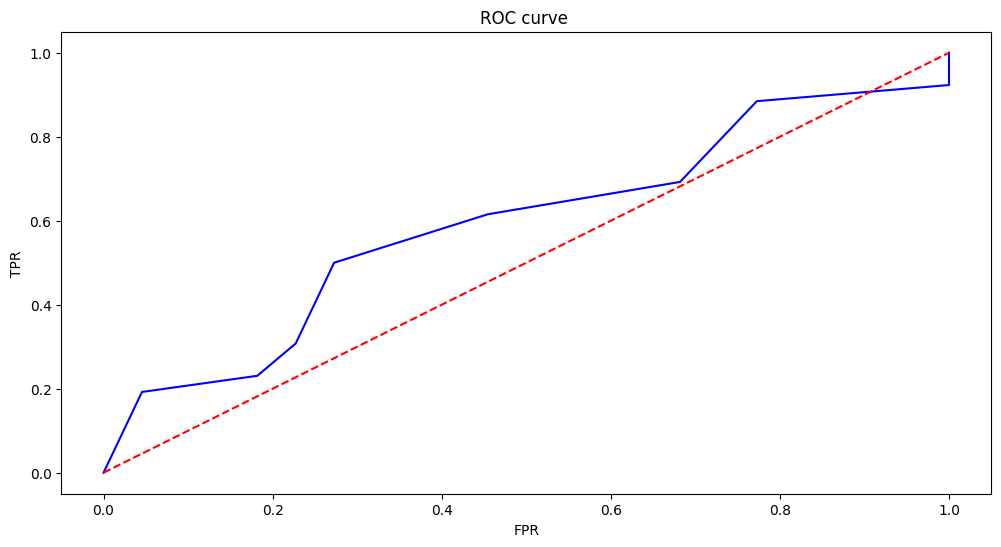

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(dt_fpr,dt_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

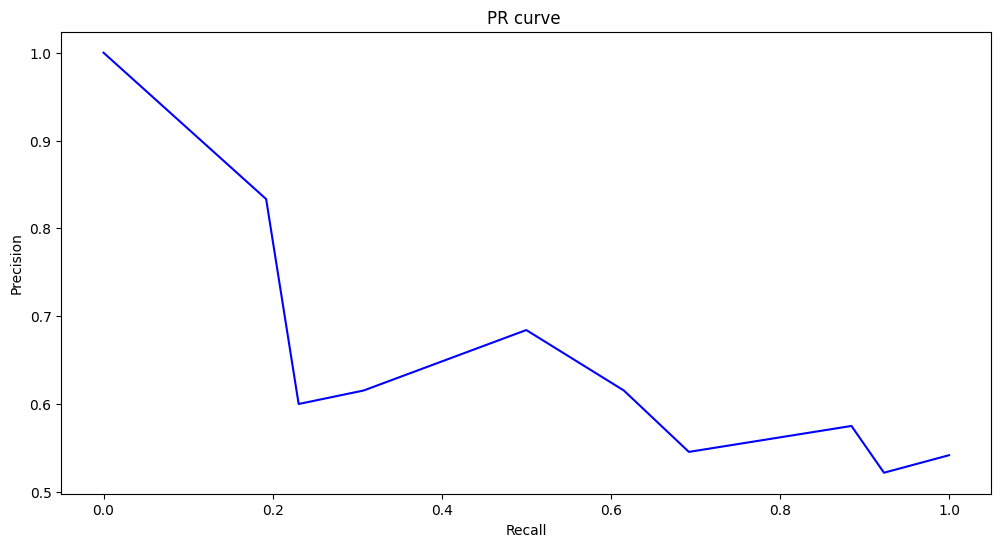

In [ ]:
dt_precision, dt_recall, dt_thr = precision_recall_curve(y_test, dt_probabilites)

plt.figure(figsize=[12,6])


plt.plot(dt_recall, dt_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# Decision Tree Classifier on With Indicators Dataset

In [ ]:
X_val_with_indicators.head()

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
106,-0.003054,-1.084846,-1.446404,0.638780,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,...,-1.011500,1.025821,1.079891,1.397770,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835
37,0.953720,0.803012,1.700263,0.638780,1.259447,-0.920268,0.850963,1.279081,1.414214,-0.895802,...,-0.119333,0.764993,0.122270,-0.017974,1.969249,-0.886405,-1.054835,-1.077184,0.948016,-1.054835
113,-0.003054,-1.084846,1.700263,-1.845585,1.259447,-0.920268,-1.175139,-0.934193,-0.707107,-0.895802,...,-1.011500,-1.707438,-1.848574,-1.464882,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
223,1.171199,0.803012,-1.446404,0.638780,-0.793999,-0.920268,0.850963,-0.365979,1.414214,0.920013,...,1.532591,-0.388282,-0.094618,-0.690421,-0.592349,-0.886405,0.948016,0.978620,-1.054835,0.948016
98,0.804884,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,-0.895802,...,-0.119333,1.113456,0.233766,0.468303,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835


In [ ]:
def kf_tuning(no_of_splits):

  kf = KFold(n_splits=no_of_splits)

  print(f"\n\n------ kfold = {no_of_splits} splits ---------\n")

  train_scores = []
  val_scores = []



  for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

      # Splitting into training and validation for that fold
      X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
      y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

      # decision Tree model
      dt2_model = DecisionTreeClassifier(random_state=42)

      # Train on training fold
      dt2_model.fit(X_train, y_trained)

      # Accuracy on training fold
      train_acc = dt2_model.score(X_train, y_trained)

      # Accuracy on validation fold
      val_acc = dt2_model.score(X_val, y_valed)

      train_scores.append(train_acc)
      val_scores.append(val_acc)

      print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

  print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
  print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


  return (np.mean(train_scores),np.mean(val_scores))


In [ ]:
kf_tuning(no_of_splits = 5)



------ kfold = 5 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5526
Fold 2: Train Acc = 1.0000, Val Acc = 0.5526
Fold 3: Train Acc = 1.0000, Val Acc = 0.6053
Fold 4: Train Acc = 1.0000, Val Acc = 0.5405
Fold 5: Train Acc = 1.0000, Val Acc = 0.4865

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5475106685633002 	std val Acc   = 0.03784265041748209


(np.float64(1.0), np.float64(0.5475106685633002))

In [ ]:
each_train_scores = []
each_val_scores = []

for splits in range(3,20):
  train_acc,val_acc = kf_tuning(no_of_splits = splits)

  each_train_scores.append(train_acc)
  each_val_scores.append(val_acc)




------ kfold = 3 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5238
Fold 2: Train Acc = 1.0000, Val Acc = 0.4762
Fold 3: Train Acc = 1.0000, Val Acc = 0.4355

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.478494623655914 	std val Acc   = 0.036095586610541054


------ kfold = 4 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.4468
Fold 2: Train Acc = 1.0000, Val Acc = 0.4894
Fold 3: Train Acc = 1.0000, Val Acc = 0.6170
Fold 4: Train Acc = 1.0000, Val Acc = 0.5106

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5159574468085106 	std val Acc   = 0.06271184107740212


------ kfold = 5 splits ---------

Fold 1: Train Acc = 1.0000, Val Acc = 0.5526
Fold 2: Train Acc = 1.0000, Val Acc = 0.5526
Fold 3: Train Acc = 1.0000, Val Acc = 0.6053
Fold 4: Train Acc = 1.0000, Val Acc = 0.5405
Fold 5: Train Acc = 1.0000, Val Acc = 0.4865

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5475106685633002 	std val Acc   = 0.03784265041748209



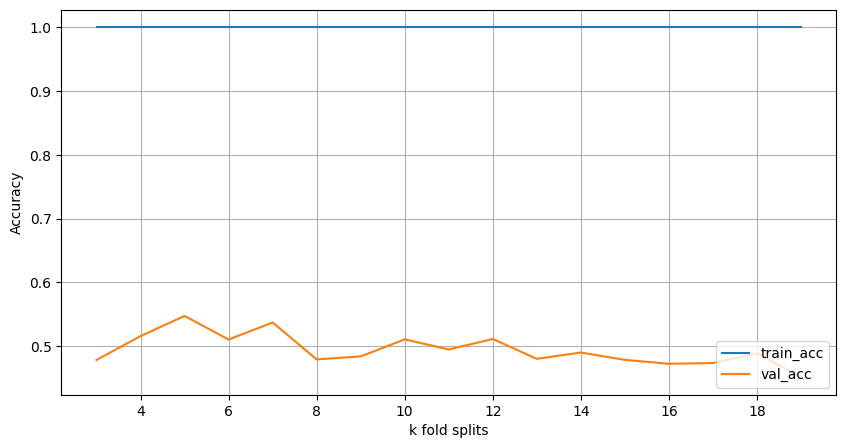

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(np.arange(3, 20, 1)), each_train_scores, label="train_acc")
plt.plot(list(np.arange(3, 20, 1)), each_val_scores, label="val_acc")

plt.legend(loc='lower right')

plt.xlabel("k fold splits")
plt.ylabel("Accuracy")
plt.grid()
plt.show()

In [ ]:
kf = KFold(n_splits=5)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # decision tree model
    dt2_model = DecisionTreeClassifier(random_state=42)

    # Train on training fold
    dt2_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = dt2_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = dt2_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 1.0000, Val Acc = 0.5526
Fold 2: Train Acc = 1.0000, Val Acc = 0.5526
Fold 3: Train Acc = 1.0000, Val Acc = 0.6053
Fold 4: Train Acc = 1.0000, Val Acc = 0.5405
Fold 5: Train Acc = 1.0000, Val Acc = 0.4865

Mean Train Acc = 1.0 	std train Acc = 0.0
Mean Val Acc   = 0.5475106685633002 	std val Acc   = 0.03784265041748209


In [ ]:
test_acc_using_kfold = dt2_model.score(X_test_with_indicators,y_test)
print(f"testing Accuracy after 5 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 5 fold cross validation = 0.7083333333333334


* Here the Training Acccuray = 100% , validation Accuracy = 54.7%
* So, clear overfitting occuring. so we have tune crierion,max_depth, min_sample_leaf,min_sample_splits,max_features, splitter

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'splitter': ['best', 'random']
}

dt2 = DecisionTreeClassifier(random_state=42)

grid2 = GridSearchCV(dt2, param_grid, cv=5, scoring='accuracy')
grid2.fit(X_train_with_indicators, y_train)

print(grid2.best_params_)
print(grid2.best_score_)


{'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'splitter': 'best'}
0.5866666666666667


In [ ]:
kf = KFold(n_splits=5)

train_scores = []
val_scores = []

for fold, (train_index, val_index) in enumerate(kf.split(X_train_val_with_indicators)):

    # Splitting into training and validation for that fold
    X_train, X_val = X_train_val_with_indicators.iloc[train_index], X_train_val_with_indicators.iloc[val_index]
    y_trained, y_valed = y_train_val.iloc[train_index], y_train_val.iloc[val_index]

    # decision tree model
    dt2_model = grid2.best_estimator_

    # Train on training fold
    dt2_model.fit(X_train, y_trained)

    # Accuracy on training fold
    train_acc = dt2_model.score(X_train, y_trained)

    # Accuracy on validation fold
    val_acc = dt2_model.score(X_val, y_valed)

    train_scores.append(train_acc)
    val_scores.append(val_acc)

    print(f"Fold {fold+1}: Train Acc = {train_acc:.4f}, Val Acc = {val_acc:.4f}")

print("\nMean Train Acc =", np.mean(train_scores),"\tstd train Acc =",np.std(train_scores))
print("Mean Val Acc   =", np.mean(val_scores),"\tstd val Acc   =",np.std(val_scores))


Fold 1: Train Acc = 0.9000, Val Acc = 0.4737
Fold 2: Train Acc = 0.8467, Val Acc = 0.5526
Fold 3: Train Acc = 0.8600, Val Acc = 0.3684
Fold 4: Train Acc = 0.8808, Val Acc = 0.6757
Fold 5: Train Acc = 0.8940, Val Acc = 0.5405

Mean Train Acc = 0.8763002207505519 	std train Acc = 0.020201064286542954
Mean Val Acc   = 0.5221906116642959 	std val Acc   = 0.10081565899198848


In [ ]:
test_acc_using_kfold = dt2_model.score(X_test_with_indicators,y_test)
print(f"testing Accuracy after 5 fold cross validation = {test_acc_using_kfold}")

testing Accuracy after 5 fold cross validation = 0.4375


## K fold cross validation model metrics & performance

In [ ]:
dt2_y_pred = dt2_model.predict(X_test_with_indicators)

print("\nconfusion matrix of Random Forest")
dt2_conf_matrix = confusion_matrix(y_test, dt2_y_pred)
print(dt2_conf_matrix) # 2D np array


confusion matrix of Random Forest
[[14  8]
 [19  7]]


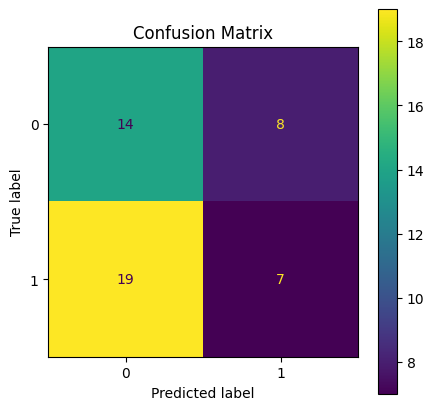

In [ ]:
fig, ax = plt.subplots(figsize=(5,5))   # optional size
ConfusionMatrixDisplay(dt2_conf_matrix).plot(ax=ax)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
np.array(y_test),dt2_y_pred

(array([0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
        1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        0, 1, 0, 1]),
 array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0,
        0, 0, 1, 1]))

In [ ]:
def precision_calc(conf):
  tp = conf[1,1]
  fp = conf[0,1]

  return tp/(tp+fp)

def recall_calc(conf):
  tp = conf[1,1]
  fn = conf[1,0]

  return tp/(tp+fn)

dt2_recall = recall_calc(dt2_conf_matrix)
dt2_precision = precision_calc(dt2_conf_matrix)
dt2_f1 = 2* (dt2_precision*dt2_recall)/(dt2_precision+dt2_recall+1e-6)

print(f"precision :  {dt2_precision}")
print(f"recall    :  {dt2_recall}")
print(f'f1Score   :  {dt2_f1}')

precision :  0.4666666666666667
recall    :  0.2692307692307692
f1Score   :  0.34146295062525867


## Threshold Tuning for class probabilites

In [ ]:
dt2_probability = dt2_model.predict_proba(X_test_with_indicators)
dt2_probability

array([[0.85714286, 0.14285714],
       [1.        , 0.        ],
       [0.75      , 0.25      ],
       [0.75      , 0.25      ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.75      , 0.25      ],
       [1.        , 0.        ],
       [0.75      , 0.25      ],
       [0.5       , 0.5       ],
       [0.28571429, 0.71428571],
       [0.5       , 0.5       ],
       [1.        , 0.        ],
       [1.        , 0.        ],
       [0.28571429, 0.71428571],
       [0.75      , 0.25      ],
       [1.        , 0.        ],
       [0.75      , 0.25      ],
       [1.        , 0.        ],
       [0.5       , 0.5       ],
       [0.28571429, 0.71428571],
       [0.75      , 0.25      ],
       [0.5       , 0.5       ],
       [1.        , 0.        ],
       [0.        , 1.        ],
       [1.        , 0.        ],
       [0.5       , 0.5       ],
       [0.8       , 0.2       ],
       [1.        , 0.        ],
       [0.16666667, 0.83333333],
       [0.

In [ ]:
dt2_probabilites = dt2_probability[:,1]

In [ ]:
dt2_fpr, dt2_tpr, dt2_thr = roc_curve(y_test,dt2_probabilites)

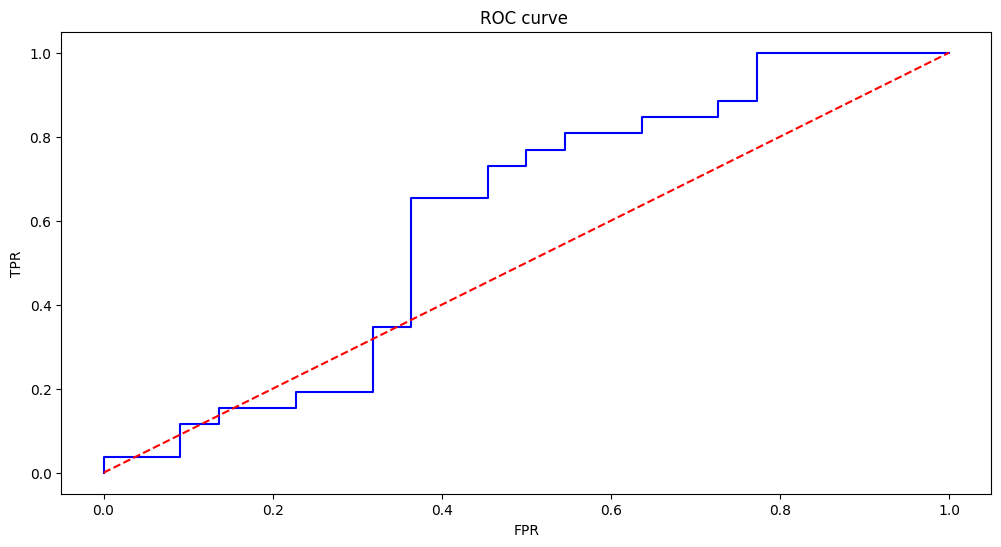

In [ ]:
plt.figure(figsize= [12,6])


plt.plot(rf2_fpr,rf2_tpr,color = "blue")

#random model
plt.plot(fpr,fpr,'--',color='red' )
plt.title('ROC curve ')
plt.xlabel('FPR')
plt.ylabel('TPR')

plt.show()

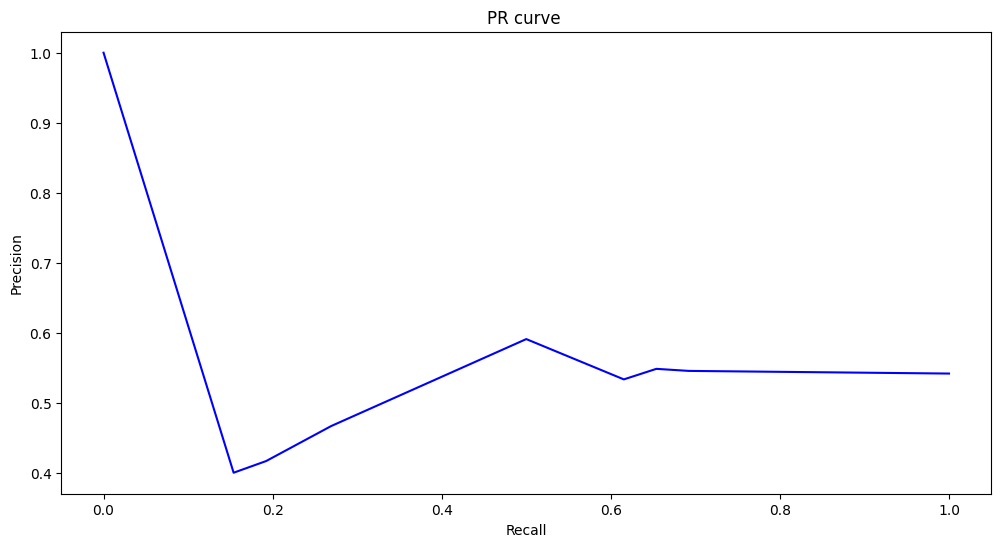

In [ ]:
dt2_precision, dt2_recall, dt2_thr = precision_recall_curve(y_test, dt2_probabilites)

plt.figure(figsize=[12,6])


plt.plot(dt2_recall, dt2_precision,color = "blue")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR curve ')


plt.show()

# Feature Importance

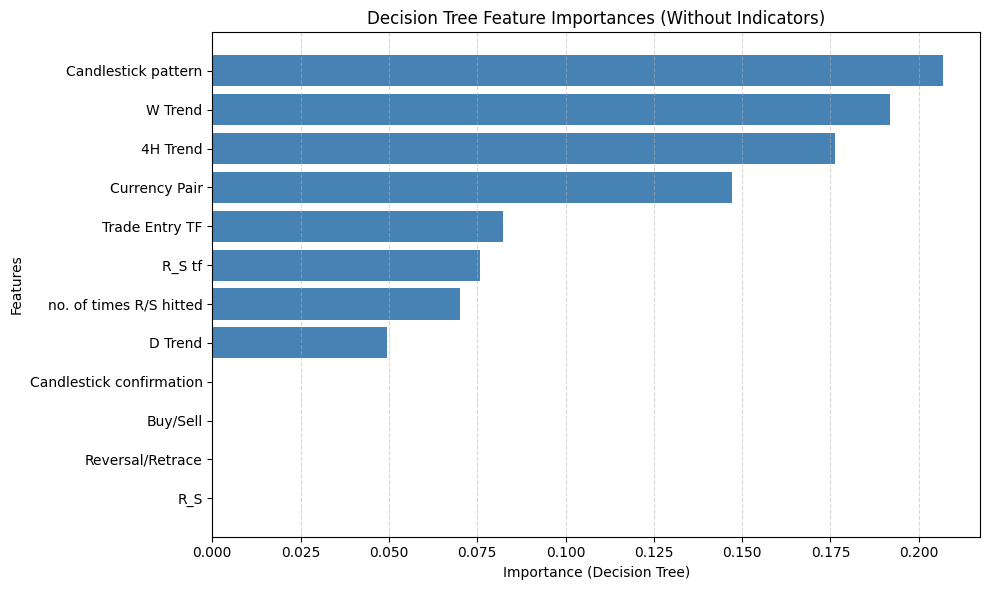

In [ ]:
importances = dt_model.feature_importances_

dt_model_df = pd.DataFrame({
    "Feature": X_train_without_indicators.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(dt_model_df["Feature"], dt_model_df["Importance"], color="steelblue")

plt.xlabel("Importance (Decision Tree)")
plt.ylabel("Features")
plt.title("Decision Tree Feature Importances (Without Indicators)")

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

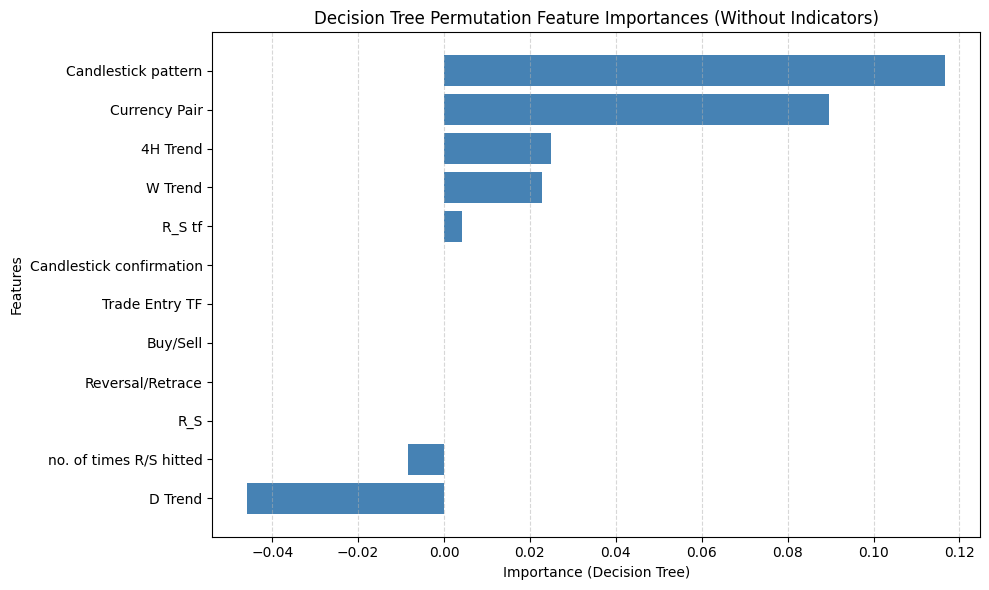

In [ ]:
result = permutation_importance(
    dt_model,
    X_test_without_indicators,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_dt_model_df = pd.DataFrame({
    "Feature": X_test_without_indicators.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(perm_dt_model_df["Feature"], perm_dt_model_df["Importance"], color="steelblue")

plt.xlabel("Importance (Decision Tree)")
plt.ylabel("Features")
plt.title("Decision Tree Permutation Feature Importances (Without Indicators)")

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

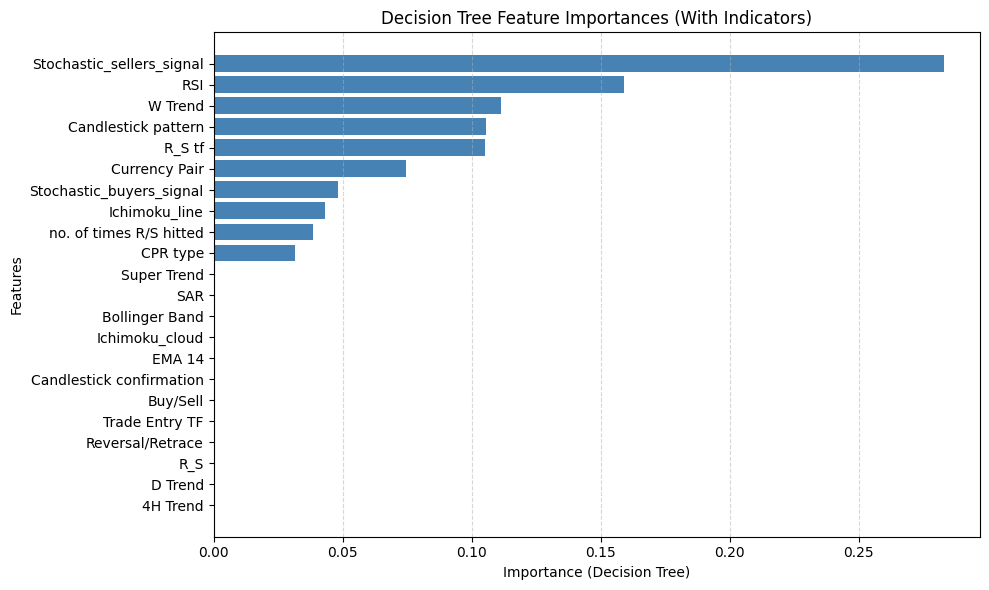

In [ ]:
importances = dt2_model.feature_importances_

dt2_model_df = pd.DataFrame({
    "Feature": X_train_with_indicators.columns,
    "Importance": importances
}).sort_values(by="Importance", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(dt2_model_df["Feature"], dt2_model_df["Importance"], color="steelblue")

plt.xlabel("Importance (Decision Tree)")
plt.ylabel("Features")
plt.title("Decision Tree Feature Importances (With Indicators)")

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

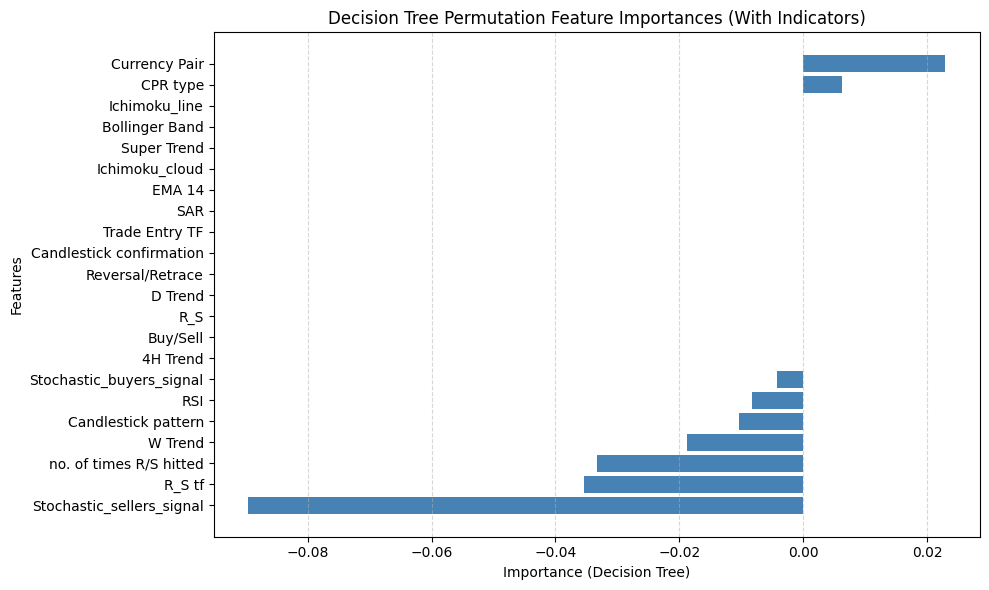

In [ ]:
result = permutation_importance(
    dt2_model,
    X_test_with_indicators,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_dt2_model_df = pd.DataFrame({
    "Feature": X_test_with_indicators.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
}).sort_values(by="Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(perm_dt2_model_df["Feature"], perm_dt2_model_df["Importance"], color="steelblue")

plt.xlabel("Importance (Decision Tree)")
plt.ylabel("Features")
plt.title("Decision Tree Permutation Feature Importances (With Indicators)")

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Improving Accuracy Using Smote Method

## For Without Technical Indicator Dataset.

In [ ]:
# train,validataion,testing data without technical indicators
X_train_without_indicators = X_train[technical_analysis_cols]
X_val_without_indicators = X_val[technical_analysis_cols]
X_test_without_indicators = X_test[technical_analysis_cols]


In [ ]:
X_merged_without_indicators = pd.concat([X_train_without_indicators,X_val_without_indicators,X_test_without_indicators],axis=0)
y_merged = pd.concat([y_train,y_val,y_test])

In [ ]:
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_merged_without_indicators, y_merged)
X_trained, X_tested, y_trained, y_tested = train_test_split(X_res, y_res, test_size=0.20, random_state=42)

In [ ]:
#best models & other new models to be tested on smote dataset without indicators
models_without_indicators=[LogisticRegression(),
        SVC(),
        RandomForestClassifier(),
        KNeighborsClassifier(),
        DecisionTreeClassifier(),
        XGBClassifier(verbose = 0),
        CatBoostClassifier(verbose=0),
        LGBMClassifier(verbose=-1)]

In [ ]:
for model in models_without_indicators:
    print(f"Model CLassification report for : {model}".split("(")[0])
    classifier=model.fit(X_trained,y_trained)
    val_preds=classifier.predict(X_tested)
    print(classification_report(y_tested,val_preds))
    print("-"*55)

Model CLassification report for : LogisticRegression
              precision    recall  f1-score   support

           0       0.68      0.61      0.64        31
           1       0.52      0.59      0.55        22

    accuracy                           0.60        53
   macro avg       0.60      0.60      0.60        53
weighted avg       0.61      0.60      0.61        53

-------------------------------------------------------
Model CLassification report for : SVC
              precision    recall  f1-score   support

           0       0.68      0.61      0.64        31
           1       0.52      0.59      0.55        22

    accuracy                           0.60        53
   macro avg       0.60      0.60      0.60        53
weighted avg       0.61      0.60      0.61        53

-------------------------------------------------------
Model CLassification report for : RandomForestClassifier
              precision    recall  f1-score   support

           0       0.70      0.

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [10:16:28] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.68      0.68      0.68        31
           1       0.55      0.55      0.55        22

    accuracy                           0.62        53
   macro avg       0.61      0.61      0.61        53
weighted avg       0.62      0.62      0.62        53

-------------------------------------------------------
Model CLassification report for : LGBMClassifier
              precision    recall  f1-score   support

           0       0.69      0.65      0.67        31
           1       0.54      0.59      0.57        22

    accuracy                           0.62        53
   macro avg       0.62      0.62      0.62        53
weighted avg       0.63      0.62      0.62        53

-------------------------------------------------------


## for With indicators dataset

In [ ]:
# train,validataion,testing data including technical indicators (i.e.technical analyis col and indicators)
X_train_with_indicators = X_train
X_val_with_indicators = X_val
X_test_with_indicators = X_test

In [ ]:
X_merged_with_indicators = pd.concat([X_train_with_indicators,X_val_with_indicators,X_test_with_indicators],axis=0)
y_merged = pd.concat([y_train,y_val,y_test],axis=0)

In [ ]:
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X_merged_with_indicators, y_merged)
X_trained, X_tested, y_trained, y_tested= train_test_split(X_res, y_res, test_size=0.20, random_state=42)

In [ ]:
#best models & other new models to be tested on smote dataset with indicators
models_with_indicators=[LogisticRegression(),
        SVC(),
        RandomForestClassifier(),
        KNeighborsClassifier(),
        DecisionTreeClassifier(),
        XGBClassifier(verbose = 0),
        CatBoostClassifier(verbose=0),
        LGBMClassifier(verbose=-1)]

In [ ]:
for model in models_with_indicators:
    print(f"Model CLassification report for : {model}".split("(")[0])
    classifier=model.fit(X_train,y_train)
    val_preds=classifier.predict(X_test)
    print(classification_report(y_test,val_preds))
    print("-"*55)

Model CLassification report for : LogisticRegression
              precision    recall  f1-score   support

           0       0.52      0.68      0.59        22
           1       0.63      0.46      0.53        26

    accuracy                           0.56        48
   macro avg       0.57      0.57      0.56        48
weighted avg       0.58      0.56      0.56        48

-------------------------------------------------------
Model CLassification report for : SVC
              precision    recall  f1-score   support

           0       0.52      0.77      0.62        22
           1       0.67      0.38      0.49        26

    accuracy                           0.56        48
   macro avg       0.59      0.58      0.55        48
weighted avg       0.60      0.56      0.55        48

-------------------------------------------------------
Model CLassification report for : RandomForestClassifier
              precision    recall  f1-score   support

           0       0.50      0.

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [10:16:46] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "verbose" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

           0       0.50      0.73      0.59        22
           1       0.62      0.38      0.48        26

    accuracy                           0.54        48
   macro avg       0.56      0.56      0.53        48
weighted avg       0.57      0.54      0.53        48

-------------------------------------------------------
Model CLassification report for : LGBMClassifier
              precision    recall  f1-score   support

           0       0.52      0.77      0.62        22
           1       0.67      0.38      0.49        26

    accuracy                           0.56        48
   macro avg       0.59      0.58      0.55        48
weighted avg       0.60      0.56      0.55        48

-------------------------------------------------------


# Testing of Models

##Without Indicators

In [ ]:
technical_analysis_cols

['Currency Pair',
 '4H Trend',
 'D Trend',
 'W Trend',
 'Reversal/Retrace',
 'R_S tf',
 'R_S',
 'Candlestick pattern',
 'Candlestick confirmation',
 'no. of times R/S hitted',
 'Trade Entry TF',
 'Buy/Sell']

In [ ]:
i = 190

In [ ]:
X_test_without_indicators.index

Index([ 69, 190, 181,   9, 127, 109, 229,  93, 150,  15, 226,  55, 192,  30,
       222, 148,  19, 112, 227,  24, 225,  10,  95, 156, 204,  25,  86, 184,
        84,  18, 147,  66,  45, 140, 125, 171, 165,  16, 211, 178, 162, 161,
       124,  60, 200, 231,  82, 117],
      dtype='int64')

In [ ]:
df.loc[i,"Profit/SL"]

np.int64(1)

In [ ]:
df.loc[i, technical_analysis_cols]

,190
Currency Pair,NZDUSD
4H Trend,Down
D Trend,Up
W Trend,Up
Reversal/Retrace,Reversal
R_S tf,4H
R_S,Resistance
Candlestick pattern,Bearish Harami
Candlestick confirmation,Instance
no. of times R/S hitted,3.0


In [ ]:
new_point_without_indicators = X_test_without_indicators.loc[[i]]
new_point_without_indicators

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,Trade Entry TF,Buy/Sell
190,-1.826718,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,0.436012,-1.175139


In [ ]:
for model in models_without_indicators:
  print("Model name :",model)
  print(model.predict(new_point_without_indicators),"\n\n")

Model name : LogisticRegression()
[0] 


Model name : SVC()
[0] 


Model name : RandomForestClassifier()
[1] 


Model name : KNeighborsClassifier()
[1] 


Model name : DecisionTreeClassifier()
[1] 


Model name : XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
[1] 


Model name : <catbo

## with indicators

In [ ]:
df.loc[i, encoding_cols]

,190
Currency Pair,NZDUSD
4H Trend,Down
D Trend,Up
W Trend,Up
Reversal/Retrace,Reversal
R_S tf,4H
R_S,Resistance
Candlestick pattern,Bearish Harami
Candlestick confirmation,Instance
Trade Entry TF,4H


In [ ]:
new_point_with_indicators = X_test_with_indicators.loc[[i]]
new_point_with_indicators

,Currency Pair,4H Trend,D Trend,W Trend,Reversal/Retrace,R_S tf,R_S,Candlestick pattern,Candlestick confirmation,no. of times R/S hitted,...,CPR type,RSI,Stochastic_buyers_signal,Stochastic_sellers_signal,EMA 14,SAR,Bollinger Band,Ichimoku_line,Ichimoku_cloud,Super Trend
190,-1.826718,-1.084846,0.334936,0.519321,-0.793999,-0.920268,-1.175139,-1.167851,-0.707107,0.012105,...,1.532591,0.747662,1.29968,0.808612,-0.503107,1.128152,-1.054835,-1.077184,0.948016,-1.054835


In [ ]:
for model in models_with_indicators:
  print("Model name :",model)
  print(model.predict(new_point_with_indicators),"\n\n")


Model name : LogisticRegression()
[0] 


Model name : SVC()
[0] 


Model name : RandomForestClassifier()
[0] 


Model name : KNeighborsClassifier()
[0] 


Model name : DecisionTreeClassifier()
[0] 


Model name : XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)
[0] 


Model name : <catbo